# Ovarian Cancer Histopathology Pipeline (upgraded)
### EfficientNet-B4 + CBAM · stain normalisation · patient-level 5-fold CV + external test · gated ABMIL · Grad-CAM/CAM++ · XAI validation

Dataset: **`ahmedaboenaba/tcga-ovarian-histological-images`** (Kaggle, downloaded with `kagglehub`).

| Pipeline step | Where in this notebook |
|---|---|
| 1. Data — development set + fully held-out external test | §2 (download, auto-discovery) and §3 (external hold-out by **TCGA tissue-source site**, or an independent folder) |
| 2. Preprocessing — Otsu/HSV tissue detection, 20× tiling, ≥ 50 % tissue, Macenko/Reinhard, resize, ImageNet norm | §4 (and §5 for the ImageNet normalisation) |
| 3. Splitting — by patient/slide *before* tiling, stratified 5-fold CV + external cohort | §3 |
| 4. Augmentation & imbalance — flips, rot90, HED jitter, blur, random crops; class-weighted CE / focal | §5 |
| 5. Training — Stage A warm-up, Stage B layer-wise LR decay, AdamW, cosine, AMP, early stopping, fixed seeds, mean ± SD | §6, §7, §10 |
| 6. Slide-level aggregation — 1792-d B4 embeddings → gated ABMIL | §8 |
| 7. Evaluation — Acc/AUC/Sens/Spec/F1/MCC, confusion matrices, 95 % CIs, Friedman/Nemenyi, DeLong, CV-vs-external | §9, §11 |
| 8. Explainability — Grad-CAM / Grad-CAM++, stitched MIL attention maps, Integrated Gradients / LIME | §12 |
| 9. XAI validation — pathologist agreement, deletion/insertion faithfulness, stability, weight-randomisation sanity check | §13 |

**Honest notes before you run it**

* The dataset's folder layout was not inspectable when this notebook was written, so §1 *auto-discovers* it (class = folder name, patient/slide/site parsed from TCGA barcodes in file names) and prints what it found. **Read that printout.** If the labels or patient IDs are not what you expect, use the override knobs in the Config cell (`LABEL_CSV`, `CLASS_MAP`, `EXTERNAL_DIR`).
* TCGA-OV is almost entirely high-grade serous carcinoma. If the dataset turns out to have a single class, the notebook stops with a clear message instead of silently training a meaningless classifier.
* Set `OVARIAN_FAST_DEV=1` (environment variable) or `CFG.FAST_DEV = True` for a tiny end-to-end smoke test before committing GPU hours.

## 0. Setup

In [1]:
import sys
print(sys.executable)

import torch
import torchvision

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

d:\seventh_sem\oc\.venv\Scripts\python.exe
Torch: 2.14.0+cu130
Torchvision: 0.29.0+cu130
CUDA: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# !nvidia-smi
# !python -m pip uninstall -y torch torchvision torchaudio
# !python -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130

In [3]:
!pip install -q kagglehub scikit-image opencv-python-headless scikit-learn scipy pandas matplotlib tqdm transforms

!pip install -q openslide-python lime     #(openslide also needs the system library; only for raw .svs slides)

import os, sys, re, gc, copy, json, math, time, random, hashlib, warnings, pickle
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (efficientnet_b4, EfficientNet_B4_Weights,
                                resnet50, ResNet50_Weights,
                                densenet121, DenseNet121_Weights)

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, matthews_corrcoef,
                             confusion_matrix, recall_score, balanced_accuracy_score)
from scipy import stats

warnings.filterwarnings("ignore")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int, deterministic: bool = False):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

print("Device:", DEVICE, "| torch", torch.__version__)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"({torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GiB)")


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#(openslide': Expected package name at the start of dependency specifier
    #(openslide
    ^
d:\seventh_sem\oc\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | torch 2.14.0+cu130
GPU: NVIDIA GeForce RTX 4060 Laptop GPU (8.0 GiB)


In [4]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", torch.cuda.get_device_properties(0).total_memory / 2**30, "GB")

PyTorch: 2.14.0+cu130
TorchVision: 0.29.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM: 7.99560546875 GB


## 1. Configuration
Every tunable lives here. Values follow the pipeline's schedule: warm-up lr ≈ 1e-3, fine-tune head lr ≈ 1e-4 decaying ×0.85 per block, AdamW + cosine, batch 16, 40 epochs, early stopping, AMP.

In [5]:
class CFG:
    # ---------------- run mode ----------------
    FAST_DEV = os.environ.get("OVARIAN_FAST_DEV", "0") == "1"   # tiny smoke test (tiny images, 1-2 epochs)

    # ---------------- data ----------------
    KAGGLE_DATASET     = "ahmedaboenaba/tcga-ovarian-histological-images"
    DATA_ROOT_OVERRIDE = os.environ.get("OVARIAN_DATA_ROOT") or None   # skip kagglehub and use a local folder
    OUT_DIR   = "./outputs"
    CACHE_DIR = "./cache"

    LABEL_CSV = None        # optional table with labels if folders are not class names, e.g. "/path/labels.csv"
    LABEL_ID_COL, LABEL_COL = None, None       # column names inside LABEL_CSV (id can be patient, slide or file stem)
    CLASS_MAP = None        # optional {"folder_or_csv_label": "class name"} to rename / merge classes
    CLASSES   = None        # None = infer from data
    MIN_PATIENTS_PER_CLASS = 5                 # classes with fewer patients cannot be 5-fold split -> dropped (with warning)

    # ---------------- external test set (held out completely) ----------------
    EXTERNAL_MODE = "site"  # "site": hold out whole TCGA tissue-source sites | "dir": independent dataset folder
                            # "patient": random patients (pseudo-external, weakest) | "none"
    EXTERNAL_DIR  = None    # for "dir": another dataset with the same class-named sub-folders (e.g. UBC-OCEAN tiles)
    EXTERNAL_FRAC = 0.20
    ANNOT_DIR     = None    # optional folder of expert masks (<image stem>.png/.npy) for the pathologist-agreement test

    # ---------------- preprocessing ----------------
    MODE          = "auto"  # "auto" | "patch" (pre-tiled images) | "wsi" (raw slides -> tiling)
    IMG_SIZE      = "auto"  # "auto": 380 (B4 native) if GPU >= 15 GiB else 256 (224 on CPU); or set an int
    TARGET_MAG    = 20      # tiling magnification
    TILE_PX       = 380     # tile edge at 20x (WSI mode)
    TISSUE_MIN    = 0.50    # drop patches with < 50 % tissue
    MAX_TILES_PER_SLIDE   = 400
    MAX_PATCHES_PER_SLIDE = None   # optional cap for pre-tiled datasets (None = keep all)
    STAIN_NORM    = "macenko"      # "macenko" | "reinhard" | "none"
    STAIN_REF_IMAGE = None         # optional path to a reference H&E image
    NUM_WORKERS   = 2

    # ---------------- splitting ----------------
    N_FOLDS = 5
    SPLIT_SEED = 42

    # ---------------- augmentation / imbalance ----------------
    CROP_SCALE = (0.70, 1.0)
    HED_THETA  = 0.05
    BLUR_P     = 0.20
    LOSS = "ce"                    # "ce" (class-weighted) | "focal"
    FOCAL_GAMMA = 2.0
    LABEL_SMOOTHING = 0.05         # only used with "ce"

    # ---------------- training ----------------
    MODEL_MAIN = "effnet_b4_cbam"
    RUN_ABLATIONS   = True                  # needed for Friedman/Nemenyi (>= 3 models)
    ABLATION_MODELS = ["effnet_b4", "resnet50"]
    ABLATION_SEEDS  = [0]                   # fewer seeds for ablations to save time
    SEEDS     = [0, 1, 2]                   # several runs -> mean +/- SD
    RUN_FOLDS = list(range(5))
    PRETRAINED = os.environ.get("OVARIAN_PRETRAINED", "1") == "1"
    BATCH_SIZE = 16
    WARMUP_EPOCHS, WARMUP_LR = 5, 1e-3
    FINETUNE_EPOCHS = 40                    # 30-50
    HEAD_LR, LLRD   = 1e-4, 0.85            # head lr; decay per block toward the input (0.8-0.9)
    WEIGHT_DECAY    = 1e-2
    EARLY_STOP_PATIENCE = 8
    AMP = True
    GRAD_CLIP = 1.0
    DROPOUT = 0.4

    # ---------------- slide-level MIL ----------------
    RUN_MIL = True
    MIL_HIDDEN, MIL_EPOCHS, MIL_LR, MIL_PATIENCE = 256, 60, 2e-4, 12
    MIL_MAX_BAG = 1000

    # ---------------- evaluation / XAI ----------------
    N_BOOT = 500
    N_XAI_SAMPLES = 16

if CFG.FAST_DEV:      # smoke-test overrides
    CFG.IMG_SIZE = 96; CFG.BATCH_SIZE = 8; CFG.WARMUP_EPOCHS = 1; CFG.FINETUNE_EPOCHS = 2
    CFG.SEEDS = [0]; CFG.ABLATION_SEEDS = [0]; CFG.RUN_FOLDS = [0, 1, 2]; CFG.NUM_WORKERS = 0
    CFG.N_BOOT = 50; CFG.N_XAI_SAMPLES = 3; CFG.MIL_EPOCHS = 4; CFG.MIL_PATIENCE = 3; CFG.TILE_PX = 128
    CFG.EARLY_STOP_PATIENCE = 2; CFG.MIL_MAX_BAG = 50

def resolve_img_size():
    if CFG.IMG_SIZE != "auto":
        size, why = int(CFG.IMG_SIZE), "set manually"
    elif DEVICE.type == "cuda" and torch.cuda.get_device_properties(0).total_memory >= 15 * 2**30:
        size, why = 380, "GPU has >= 15 GiB -> B4 native 380x380"
    elif DEVICE.type == "cuda":
        size, why = 256, "GPU memory limited (< 15 GiB) -> 256x256 (B4 is memory-heavy)"
    else:
        size, why = 224, "no GPU -> 224x224"
    print(f"Model input size: {size}x{size}  ({why})")
    return size

CFG.IMG_SIZE = resolve_img_size()
IMG_SIZE = CFG.IMG_SIZE
OUT, CACHE = Path(CFG.OUT_DIR), Path(CFG.CACHE_DIR)
for d in (OUT, OUT / "runs", OUT / "figs", OUT / "tables", CACHE):
    d.mkdir(parents=True, exist_ok=True)
print("FAST_DEV:", CFG.FAST_DEV)

Model input size: 256x256  (GPU memory limited (< 15 GiB) -> 256x256 (B4 is memory-heavy))
FAST_DEV: False


## 2. Data — download & auto-discovery
Downloads the dataset with the exact `kagglehub` call you supplied, then scans it: image files vs. raw slides, label tables, class folders, TCGA barcodes (`TCGA-<TSS>-<patient>-<sample>-...`).
The **tissue-source-site (TSS)** code inside the barcode identifies the contributing hospital, which makes a *genuine site-level external hold-out* possible from a single TCGA download.

In [6]:
if CFG.DATA_ROOT_OVERRIDE:
    path = CFG.DATA_ROOT_OVERRIDE
else:
    import kagglehub
    # Download latest version
    path = kagglehub.dataset_download("ahmedaboenaba/tcga-ovarian-histological-images")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\ADMIN\.cache\kagglehub\datasets\ahmedaboenaba\tcga-ovarian-histological-images\versions\1


In [7]:
IMG_EXT   = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp", ".webp"}
SLIDE_EXT = {".svs", ".ndpi", ".mrxs", ".scn", ".vms", ".vmu", ".svslide"}
TABLE_EXT = {".csv", ".tsv", ".xlsx", ".xls", ".json"}
GENERIC_DIRS = {"train", "test", "val", "valid", "validation", "images", "image", "imgs", "img", "data",
                "dataset", "tiles", "tile", "patches", "patch", "raw", "all", "tcga", "tcga-ov", "tcga_ov"}
RE_PATIENT = re.compile(r"TCGA-[A-Z0-9]{2}-[A-Z0-9]{4}", re.I)
RE_SLIDE   = re.compile(r"TCGA-[A-Z0-9]{2}-[A-Z0-9]{4}-\d{2}[A-Z]-\d{2}-[A-Z0-9]+", re.I)
RE_XY      = re.compile(r"[xX][_=\-]?(\d+)[_,\-\s]+[yY][_=\-]?(\d+)")

def strip_wrappers(root):
    """Descend through folders that contain nothing but a single sub-folder."""
    root = Path(root)
    while True:
        kids = [p for p in root.iterdir() if not p.name.startswith(".")]
        if len(kids) == 1 and kids[0].is_dir():
            root = kids[0]
        else:
            return root

def scan_files(root):
    imgs, slides, tables = [], [], []
    for p in Path(root).rglob("*"):
        if not p.is_file():
            continue
        e = p.suffix.lower()
        if e in IMG_EXT: imgs.append(p)
        elif e in SLIDE_EXT: slides.append(p)
        elif e in TABLE_EXT: tables.append(p)
    return sorted(imgs), sorted(slides), sorted(tables)

def infer_label_from_path(p, root):
    parts = Path(p).relative_to(root).parts[:-1]
    for d in reversed(parts):
        if d.lower() in GENERIC_DIRS or RE_SLIDE.search(d) or RE_PATIENT.search(d):
            continue
        return d
    return None

def parse_ids(p, root):
    rel = str(Path(p).relative_to(root))
    stem = Path(p).stem
    m_pat, m_sl = RE_PATIENT.search(rel), RE_SLIDE.search(rel)
    out = {"patient_id": None, "slide_id": None, "site": None, "group_source": "none", "x": np.nan, "y": np.nan}
    if m_pat:
        out["patient_id"] = m_pat.group(0).upper()
        out["site"] = out["patient_id"].split("-")[1]
        out["slide_id"] = m_sl.group(0).upper() if m_sl else out["patient_id"]
        out["group_source"] = "tcga_barcode"
    else:
        parts = Path(p).relative_to(root).parts[:-1]
        deeper = [d for d in parts[1:] if d.lower() not in GENERIC_DIRS] if len(parts) > 1 else []
        if deeper:                                           # e.g. <class>/<slide_folder>/<tile>.png
            out["patient_id"] = out["slide_id"] = deeper[-1]; out["group_source"] = "folder"
        else:
            prefix = re.sub(r"([_\-\s]*(x|y|tile|patch|row|col|r|c)?[_\-\s]*\d+)+$", "", stem, flags=re.I)
            if prefix and prefix != stem:
                out["patient_id"] = out["slide_id"] = prefix; out["group_source"] = "filename_prefix"
    m = RE_XY.search(stem)
    if m:
        out["x"], out["y"] = float(m.group(1)), float(m.group(2))
    return out

def build_items(root, is_external=False, verbose=True):
    """One row per image (patch mode) or per slide file (wsi mode)."""
    root = strip_wrappers(root)
    imgs, slides, tables = scan_files(root)
    if verbose:
        print(f"Root: {root}\n  images: {len(imgs):,} | raw slides: {len(slides):,} | tables: {[t.name for t in tables][:10]}")
    kind = "patch" if imgs else "slide"
    files = imgs if imgs else slides
    if imgs and slides and verbose:
        print("  (both images and raw slides found - using the images; set MODE='wsi' and point to slides to force tiling)")
    if not files:
        raise FileNotFoundError(f"No images or slides found under {root}")
    rows = []
    for p in files:
        r = {"path": str(p), "kind": kind, "label_name": infer_label_from_path(p, root), "stem": p.stem}
        r.update(parse_ids(p, root)); rows.append(r)
    df = pd.DataFrame(rows)
    if is_external:
        for c in ("patient_id", "slide_id"):
            df[c] = "EXT_" + df[c].fillna(df["stem"]).astype(str)
        df["site"] = "EXT"
    return df, tables

def apply_label_csv(df, csv_path, id_col, label_col):
    tab = pd.read_csv(csv_path, sep=None, engine="python")
    tab[id_col] = tab[id_col].astype(str).str.strip()
    lab = dict(zip(tab[id_col].str.lower(), tab[label_col].astype(str)))
    best, best_cov = None, -1
    for key in ("patient_id", "slide_id", "stem"):
        cov = df[key].astype(str).str.lower().isin(lab).mean()
        if cov > best_cov: best, best_cov = key, cov
    print(f"Label CSV joined on '{best}' (coverage {best_cov:.1%})")
    df["label_name"] = df[best].astype(str).str.lower().map(lab)
    return df

items, tables = build_items(strip_wrappers(path))
if CFG.LABEL_CSV:
    items = apply_label_csv(items, CFG.LABEL_CSV, CFG.LABEL_ID_COL, CFG.LABEL_COL)
if CFG.CLASS_MAP:
    items["label_name"] = items["label_name"].map(lambda v: CFG.CLASS_MAP.get(v, v))

print("\n--- first rows ---");  display(items.head(8)) if "display" in globals() else print(items.head(8))
print("\n--- label counts (before filtering) ---"); print(items["label_name"].value_counts(dropna=False).head(30))
print("\n--- how patient/slide IDs were obtained ---"); print(items["group_source"].value_counts())
for t in tables[:5]:
    try:
        print(f"\nTable found: {t.name}"); print(pd.read_csv(t, sep=None, engine="python", nrows=3))
    except Exception as e:
        print("  (could not preview:", e, ")")

Root: C:\Users\ADMIN\.cache\kagglehub\datasets\ahmedaboenaba\tcga-ovarian-histological-images\versions\1\ovarian
  images: 33,110 | raw slides: 0 | tables: []

--- first rows ---
                                                path   kind  label_name  \
0  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   
1  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   
2  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   
3  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   
4  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   
5  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   
6  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   
7  C:\Users\ADMIN\.cache\kagglehub\datasets\ahmed...  patch  non-tumour   

                                  stem    patient_id                 slide_id  \
0  TCGA-13-A5FT-01Z-00-DX1_10240_16896  TCGA-13-A5FT  TCGA-13-A5

In [8]:
def finalize_classes(items, cfg):
    df = items.dropna(subset=["label_name"]).copy()
    if len(df) < len(items):
        print(f"Dropped {len(items)-len(df):,} rows with no label.")
    # ---- patient-grouping sanity: never allow a silent patch-level split
    grp = df["patient_id"]
    n_groups = grp.nunique(dropna=True)
    bad = grp.isna().all() or n_groups < 2 * cfg.N_FOLDS or (grp.value_counts(normalize=True).iloc[0] > 0.5 if n_groups else True)
    if bad and df["group_source"].ne("tcga_barcode").any():
        print("WARNING: could not derive reliable patient/slide IDs from the file layout "
              f"(found {n_groups} groups). Each file is treated as its own patient -> patch-level leakage is possible!\n"
              "         Provide IDs via LABEL_CSV or rename files to contain TCGA barcodes.")
        df["patient_id"] = df["slide_id"] = df["stem"] + "_" + df.index.astype(str)
        df["group_source"] = "none(!)"
    else:
        df["patient_id"] = df["patient_id"].fillna(df["stem"]); df["slide_id"] = df["slide_id"].fillna(df["patient_id"])
    # ---- classes
    classes = list(cfg.CLASSES) if cfg.CLASSES else sorted(df["label_name"].unique())
    df = df[df["label_name"].isin(classes)]
    per_cls = df.groupby("label_name")["patient_id"].nunique()
    small = per_cls[per_cls < cfg.MIN_PATIENTS_PER_CLASS].index.tolist()
    if small:
        print(f"WARNING: dropping classes with < {cfg.MIN_PATIENTS_PER_CLASS} patients: {small}")
        classes = [c for c in classes if c not in small]; df = df[df["label_name"].isin(classes)]
    if len(classes) < 2:
        raise RuntimeError(
            "Fewer than 2 usable classes were found (" + str(dict(per_cls)) + ").\n"
            "TCGA-OV slides are almost all high-grade serous, so this dataset may not carry a subtype label in its folder names.\n"
            "Fix: set CFG.LABEL_CSV / LABEL_ID_COL / LABEL_COL (e.g. a clinical table with histology or tumour-vs-normal), "
            "or CFG.CLASS_MAP, then re-run this cell.")
    df["label"] = df["label_name"].map({c: i for i, c in enumerate(classes)}).astype(int)
    return df.reset_index(drop=True), classes

items, CLASSES = finalize_classes(items, CFG)
NUM_CLASSES = len(CLASSES)
print(f"\nClasses ({NUM_CLASSES}): {CLASSES}")
summary = items.groupby("label_name").agg(files=("path", "size"), patients=("patient_id", "nunique"),
                                          slides=("slide_id", "nunique"), sites=("site", "nunique"))
display(summary) if "display" in globals() else print(summary)
if items["kind"].iloc[0] == "patch":
    print("Patches per slide  -> median:", int(items.groupby("slide_id").size().median()),
          "| max:", int(items.groupby("slide_id").size().max()))
MODE = CFG.MODE if CFG.MODE != "auto" else ("wsi" if items["kind"].iloc[0] == "slide" else "patch")
print("MODE:", MODE)


Classes (2): ['non-tumour', 'tumour']
            files  patients  slides  sites
label_name                                
non-tumour  13363        34      34      9
tumour      19747        39      39     11
Patches per slide  -> median: 634 | max: 2360
MODE: patch


## 3. Splitting — by patient/slide **before** tiling
1. **External test set** (never used for training, early stopping, or model selection): whole TCGA tissue-source *sites* (default), or an independent dataset folder (`EXTERNAL_DIR`, e.g. UBC-OCEAN tiles).
2. **Development set**: `StratifiedGroupKFold` (5 folds), grouped by patient, so no patient — and therefore no slide or patch — is ever in two folds.
3. Because the split is applied to the *item table* (patch files, or raw slide files in WSI mode), tiling happens afterwards and cannot leak.

In [9]:
def choose_external_sites(items, frac, seed, n_folds, n_classes, n_tries=400):
    pat = items.drop_duplicates("patient_id")
    site_n = pat.groupby("site").size()
    total, rng, best = len(pat), np.random.RandomState(seed), None
    for _ in range(n_tries):
        chosen, n = [], 0
        for s in rng.permutation(site_n.index.to_numpy()):
            if n >= frac * total: break
            chosen.append(s); n += site_n[s]
        ext_p = set(pat.loc[pat.site.isin(chosen), "patient_id"])
        ext, dev = items[items.patient_id.isin(ext_p)], items[~items.patient_id.isin(ext_p)]
        dev_ok = dev.label.nunique() == n_classes and dev.groupby("label").patient_id.nunique().min() >= n_folds
        score = (dev_ok, ext.label.nunique(), -abs(n / total - frac))
        if best is None or score > best[0]:
            best = (score, chosen)
    return best[1]

def make_splits(items, cfg, classes):
    items = items.copy(); items["split"] = "dev"; items["fold"] = -1
    mode = cfg.EXTERNAL_MODE
    ext_extra = None
    if mode == "site" and items["site"].nunique() < 3:
        print("Fewer than 3 sites available -> falling back to a patient-level pseudo-external hold-out."); mode = "patient"
    if mode == "site":
        sites = choose_external_sites(items, cfg.EXTERNAL_FRAC, cfg.SPLIT_SEED, cfg.N_FOLDS, len(classes))
        items.loc[items.site.isin(sites), "split"] = "ext"
        print(f"External test = whole sites {sorted(sites)} (genuine site-level hold-out).")
    elif mode == "patient":
        pl = items.drop_duplicates("patient_id")
        k = max(2, round(1 / cfg.EXTERNAL_FRAC))
        sgkf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=cfg.SPLIT_SEED)
        _, e_idx = next(sgkf.split(pl, pl.label, pl.patient_id))
        items.loc[items.patient_id.isin(set(pl.iloc[e_idx].patient_id)), "split"] = "ext"
        print("External test = random held-out PATIENTS. NOTE: same sites/scanners as training -> optimistic; "
              "prefer EXTERNAL_MODE='site' or 'dir'.")
    elif mode == "dir":
        ext_items, _ = build_items(cfg.EXTERNAL_DIR, is_external=True)
        ext_items = ext_items[ext_items.label_name.isin(classes)].copy()
        ext_items["label"] = ext_items.label_name.map({c: i for i, c in enumerate(classes)}).astype(int)
        ext_items["split"], ext_items["fold"] = "ext", -1
        items = pd.concat([items, ext_items], ignore_index=True)
        print(f"External test = independent dataset '{cfg.EXTERNAL_DIR}' ({len(ext_items):,} files).")
    elif mode == "none":
        print("WARNING: no external test set - generalisation cannot be assessed.")
    dev_mask = items.split == "dev"
    dev = items[dev_mask]
    sgkf = StratifiedGroupKFold(n_splits=cfg.N_FOLDS, shuffle=True, random_state=cfg.SPLIT_SEED)
    for f, (_, va) in enumerate(sgkf.split(dev, dev.label, dev.patient_id)):
        items.loc[dev.index[va], "fold"] = f
    return items

def assert_no_leakage(df):
    dev, ext = df[df.split == "dev"], df[df.split == "ext"]
    per_patient_folds = dev.groupby("patient_id")["fold"].nunique()
    assert (per_patient_folds == 1).all(), "A patient appears in more than one CV fold!"
    per_slide_folds = dev.groupby("slide_id")["fold"].nunique()
    assert (per_slide_folds == 1).all(), "A slide appears in more than one CV fold!"
    assert not (set(dev.patient_id) & set(ext.patient_id)), "A patient is in both development and external sets!"
    if "site" in df and df.site.notna().all() and CFG.EXTERNAL_MODE == "site":
        assert not (set(dev.site) & set(ext.site)), "A site is in both development and external sets!"
    print("Leakage checks passed: no patient/slide shared between folds or with the external set.")

items = make_splits(items, CFG, CLASSES)
assert_no_leakage(items)

tab = (items.assign(fold=items.fold.where(items.split == "dev", other=-1))
       .groupby(["split", "fold", "label_name"]).agg(patients=("patient_id", "nunique"), files=("path", "size")).reset_index())
display(tab) if "display" in globals() else print(tab)
missing = [f for f in range(CFG.N_FOLDS) if items[(items.fold == f)].label.nunique() < NUM_CLASSES]
if missing:
    print(f"WARNING: folds {missing} do not contain every class (too few patients in some class); AUC may be NaN there.")
items.drop(columns=["stem"]).to_csv(OUT / "tables" / "item_splits.csv", index=False)

External test = whole sites ['13', '57', 'VG'] (genuine site-level hold-out).
Leakage checks passed: no patient/slide shared between folds or with the external set.
   split  fold  label_name  patients  files
0    dev     0  non-tumour         4   2587
1    dev     0      tumour         5   2949
2    dev     1  non-tumour         7   2610
3    dev     1      tumour         8   2520
4    dev     2  non-tumour         5   2804
5    dev     2      tumour         5   3232
6    dev     3  non-tumour         5   2307
7    dev     3      tumour         6   3284
8    dev     4  non-tumour         6   2561
9    dev     4      tumour         7   3063
10   ext    -1  non-tumour         7    494
11   ext    -1      tumour         8   4699


## 4. Preprocessing
* **Tissue detection** — HSV-saturation + Otsu (threshold clamped to a sane range so uniformly-stained tiles are not split in half) with morphological clean-up.
* **20× tiling** (raw slides, needs `openslide`): tissue mask on a thumbnail → grid of `TILE_PX` tiles at 20× → keep tiles with ≥ 50 % tissue.
* **Stain normalisation** — Macenko (reference stain matrix fitted on one representative image) or Reinhard (LAB moment matching).
* **Resize** to the model input (`IMG_SIZE`, stated in the Config cell), then ImageNet mean/std at load time (§5).
Processed patches are cached on disk, so this runs once per (size, stain) setting.

In [10]:
def detect_tissue_mask(rgb, sat_floor=15, sat_cap=40, white=230):
    """HSV saturation + Otsu. The Otsu threshold is clamped to [sat_floor, sat_cap] so that
    (i) blank tiles do not turn noise into 'tissue' and (ii) fully-stained tiles are not split at an arbitrary level."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    s = hsv[..., 1]
    t, _ = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    t = float(np.clip(t, sat_floor, sat_cap))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = ((s > t) & (gray < white)).astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(cv2.morphologyEx(mask, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    return mask.astype(bool)

def tissue_fraction(rgb):
    return float(detect_tissue_mask(rgb).mean())

# ---------------- stain normalisation ----------------
class MacenkoNormalizer:
    def __init__(self, Io=240, alpha=1, beta=0.15):
        self.Io, self.alpha, self.beta, self.fitted = Io, alpha, beta, False
        self.HE_ref = np.array([[0.5626, 0.2159], [0.7201, 0.8012], [0.4062, 0.5581]])
        self.maxC_ref = np.array([1.9705, 1.0308])

    def _stain_matrix(self, rgb):
        OD = -np.log((rgb.reshape(-1, 3).astype(np.float64) + 1) / self.Io)
        OD = OD[~np.any(OD < self.beta, axis=1)]
        if len(OD) < 200: raise ValueError("too little stained tissue")
        _, V = np.linalg.eigh(np.cov(OD.T)); V = V[:, 1:3]
        if V[0, 0] < 0: V[:, 0] *= -1
        if V[0, 1] < 0: V[:, 1] *= -1
        phi = np.arctan2(OD @ V[:, 1], OD @ V[:, 0])
        lo, hi = np.percentile(phi, self.alpha), np.percentile(phi, 100 - self.alpha)
        v1, v2 = V @ np.array([np.cos(lo), np.sin(lo)]), V @ np.array([np.cos(hi), np.sin(hi)])
        HE = np.array([v1, v2]).T if v1[0] > v2[0] else np.array([v2, v1]).T   # haematoxylin first
        return HE

    def _concentrations(self, rgb, HE):
        OD = -np.log((rgb.reshape(-1, 3).astype(np.float64) + 1) / self.Io)
        return np.linalg.pinv(HE) @ OD.T

    def fit(self, rgb_ref):
        HE = self._stain_matrix(rgb_ref)
        C = self._concentrations(rgb_ref, HE)
        self.HE_ref, self.maxC_ref, self.fitted = HE, np.percentile(C, 99, axis=1), True
        return self

    def transform(self, rgb):
        try:
            h, w, _ = rgb.shape
            HE = self._stain_matrix(rgb)
            C = self._concentrations(rgb, HE)
            maxC = np.percentile(C, 99, axis=1)
            C2 = C * (self.maxC_ref / (maxC + 1e-8))[:, None]
            out = self.Io * np.exp(-self.HE_ref @ C2)
            return np.clip(out.T.reshape(h, w, 3), 0, 255).astype(np.uint8), True
        except Exception:                       # blank / degenerate tile -> leave untouched
            return rgb, False

class ReinhardNormalizer:
    fitted = False
    def fit(self, rgb_ref):
        lab = cv2.cvtColor(rgb_ref, cv2.COLOR_RGB2LAB).astype(np.float32)
        m = detect_tissue_mask(rgb_ref)
        px = lab[m] if m.sum() > 100 else lab.reshape(-1, 3)
        self.mu, self.sd, self.fitted = px.mean(0), px.std(0) + 1e-6, True
        return self

    def transform(self, rgb):
        if not self.fitted: return rgb, False
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
        m = detect_tissue_mask(rgb)
        px = lab[m] if m.sum() > 100 else lab.reshape(-1, 3)
        mu, sd = px.mean(0), px.std(0) + 1e-6
        lab = (lab - mu) / sd * self.sd + self.mu
        out = cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)
        return out, True

def read_rgb(p):
    return np.array(Image.open(p).convert("RGB"))

def pick_reference_patch(paths, n=60, seed=0):
    rng = np.random.RandomState(seed)
    cand = [paths[i] for i in rng.permutation(len(paths))[:n]]
    scored = []
    for p in cand:
        try:
            im = read_rgb(p)
            if tissue_fraction(im) > 0.8:
                scored.append((cv2.cvtColor(im, cv2.COLOR_RGB2HSV)[..., 1].mean(), p))
        except Exception:
            pass
    if not scored: return None
    scored.sort(); return scored[len(scored) // 2][1]        # median-saturation image = typical stain

def build_normalizer(items, cfg):
    if cfg.STAIN_NORM == "none":
        return None
    norm = MacenkoNormalizer() if cfg.STAIN_NORM == "macenko" else ReinhardNormalizer()
    ref = cfg.STAIN_REF_IMAGE or (pick_reference_patch(items[items.kind == "patch"].path.tolist())
                                  if (items.kind == "patch").any() else None)
    if ref is None:
        print("No reference image available yet (WSI mode) - will fit the normaliser on the first tissue tile.")
        return norm
    try:
        norm.fit(read_rgb(ref)); print(f"{cfg.STAIN_NORM} reference:", Path(ref).name)
    except Exception as e:
        print("Reference fit failed, using default Macenko reference stains:", e)
    return norm

NORMALIZER = build_normalizer(items[items.split.isin(["dev", "ext"])], CFG)

macenko reference: TCGA-OY-A56P-01Z-00-DX1_3072_30208.jpg


In [11]:
def process_array(rgb, normalizer, size, tissue_min):
    """tissue check -> stain normalisation -> resize. Returns (uint8 image | None, tissue fraction, normalised_ok)."""
    frac = tissue_fraction(rgb)
    if frac < tissue_min:
        return None, frac, False
    ok = False
    if normalizer is not None:
        rgb, ok = normalizer.transform(rgb)
    if rgb.shape[0] != size or rgb.shape[1] != size:
        rgb = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)
    return rgb, frac, ok

PREP_TAG = f"{IMG_SIZE}_{CFG.STAIN_NORM}_{CFG.TISSUE_MIN}"
PREP_DIR = CACHE / PREP_TAG; PREP_DIR.mkdir(parents=True, exist_ok=True)
PREP_INDEX_FILE = PREP_DIR / "index.pkl"
PREP_INDEX = pickle.load(open(PREP_INDEX_FILE, "rb")) if PREP_INDEX_FILE.exists() else {}

def _key(*parts):
    return hashlib.sha1("|".join(map(str, parts)).encode()).hexdigest()[:20]

def _prep_one_patch(path):
    k = _key(path); out = PREP_DIR / f"{k}.png"
    if k in PREP_INDEX:
        kept, frac = PREP_INDEX[k]
        return (str(out) if kept else None), frac, k
    try:
        img, frac, ok = process_array(read_rgb(path), NORMALIZER, IMG_SIZE, CFG.TISSUE_MIN)
    except Exception as e:
        PREP_INDEX[k] = (False, 0.0); return None, 0.0, k
    if img is None:
        PREP_INDEX[k] = (False, frac); return None, frac, k
    Image.fromarray(img).save(out, compress_level=1)
    PREP_INDEX[k] = (True, frac)
    return str(out), frac, k

def tile_slide(slide_path, meta, cfg, normalizer, size, rng):
    """Tile ONE raw slide at cfg.TARGET_MAG (needs openslide). Returns rows for the patch table."""
    try:
        import openslide
    except ImportError as e:
        raise ImportError("Raw slides found: pip install openslide-python (+ the OpenSlide system library).") from e
    sl = openslide.OpenSlide(slide_path)
    obj = float(sl.properties.get("openslide.objective-power") or 40.0)
    ds20 = max(obj / cfg.TARGET_MAG, 1.0)                  # level-0 pixels per 20x pixel
    level = sl.get_best_level_for_downsample(ds20)
    lvl_ds = sl.level_downsamples[level]
    read_px = max(1, int(round(cfg.TILE_PX * ds20 / lvl_ds)))
    step0 = int(round(cfg.TILE_PX * ds20))                 # tile edge in level-0 pixels
    W, H = sl.dimensions
    thumb = np.array(sl.get_thumbnail((2000, 2000)).convert("RGB"))
    sx, sy = W / thumb.shape[1], H / thumb.shape[0]
    mask = detect_tissue_mask(thumb)
    thumb_path = CACHE / "thumbs" / f"{meta['slide_id']}.png"; thumb_path.parent.mkdir(exist_ok=True)
    Image.fromarray(thumb).save(thumb_path)
    cand = []
    for y0 in range(0, H - step0 + 1, step0):
        for x0 in range(0, W - step0 + 1, step0):
            m = mask[int(y0 / sy): int((y0 + step0) / sy) + 1, int(x0 / sx): int((x0 + step0) / sx) + 1]
            if m.size and m.mean() >= cfg.TISSUE_MIN * 0.8:      # cheap pre-filter, exact check below
                cand.append((x0, y0))
    rng.shuffle(cand)
    rows = []
    for (x0, y0) in cand:
        if len(rows) >= cfg.MAX_TILES_PER_SLIDE: break
        tile = np.array(sl.read_region((x0, y0), level, (read_px, read_px)).convert("RGB"))
        if read_px != cfg.TILE_PX:
            tile = cv2.resize(tile, (cfg.TILE_PX, cfg.TILE_PX), interpolation=cv2.INTER_AREA)
        if normalizer is not None and not normalizer.fitted and tissue_fraction(tile) > 0.8:
            normalizer.fit(tile)                               # WSI mode: first good tile becomes the stain reference
        img, frac, _ = process_array(tile, normalizer, size, cfg.TISSUE_MIN)
        if img is None: continue
        out = PREP_DIR / f"{_key(slide_path, x0, y0)}.png"
        Image.fromarray(img).save(out, compress_level=1)
        rows.append({**meta, "img_path": str(out), "tissue_frac": frac, "x": x0, "y": y0,
                     "step0": step0, "thumb_path": str(thumb_path), "slide_dims": (W, H)})
    sl.close()
    return rows

META_COLS = ["label", "label_name", "patient_id", "slide_id", "site", "split", "fold", "x", "y"]

def prepare_patches(items, cfg):
    parts = []
    patches = items[items.kind == "patch"].copy()
    if len(patches):
        if cfg.MAX_PATCHES_PER_SLIDE:
            patches = (patches.sample(frac=1.0, random_state=cfg.SPLIT_SEED)
                       .groupby("slide_id").head(cfg.MAX_PATCHES_PER_SLIDE))
        with ThreadPoolExecutor(max_workers=max(1, os.cpu_count() or 1)) as ex:
            res = list(tqdm(ex.map(_prep_one_patch, patches.path.tolist()), total=len(patches), desc="preprocess patches"))
        patches["img_path"] = [r[0] for r in res]; patches["tissue_frac"] = [r[1] for r in res]
        n0 = len(patches); patches = patches[patches.img_path.notna()]
        print(f"Tissue filter (>= {cfg.TISSUE_MIN:.0%}): kept {len(patches):,}/{n0:,} patches")
        parts.append(patches[META_COLS + ["img_path", "tissue_frac"]])
    slides = items[items.kind == "slide"]
    if len(slides):                                          # split was already done on slide/patient level
        rng = np.random.RandomState(cfg.SPLIT_SEED)
        rows = []
        for _, r in tqdm(slides.iterrows(), total=len(slides), desc="tiling slides"):
            rows += tile_slide(r.path, r[META_COLS].to_dict() | {"slide_id": r.slide_id}, cfg, NORMALIZER, IMG_SIZE, rng)
        parts.append(pd.DataFrame(rows))
    pickle.dump(PREP_INDEX, open(PREP_INDEX_FILE, "wb"))
    return pd.concat(parts, ignore_index=True)

patch_df = prepare_patches(items, CFG)
patch_df["pid"] = np.arange(len(patch_df))
dev_df = patch_df[patch_df.split == "dev"].reset_index(drop=True)
ext_df = patch_df[patch_df.split == "ext"].reset_index(drop=True)
print(f"Development patches: {len(dev_df):,} | External patches: {len(ext_df):,}")
assert_no_leakage(patch_df)
patch_df.to_csv(OUT / "tables" / "patch_table.csv", index=False)

preprocess patches: 100%|██████████| 33110/33110 [00:00<00:00, 775556.12it/s]

Tissue filter (>= 50%): kept 29,673/33,110 patches
Development patches: 24,708 | External patches: 4,965
Leakage checks passed: no patient/slide shared between folds or with the external set.


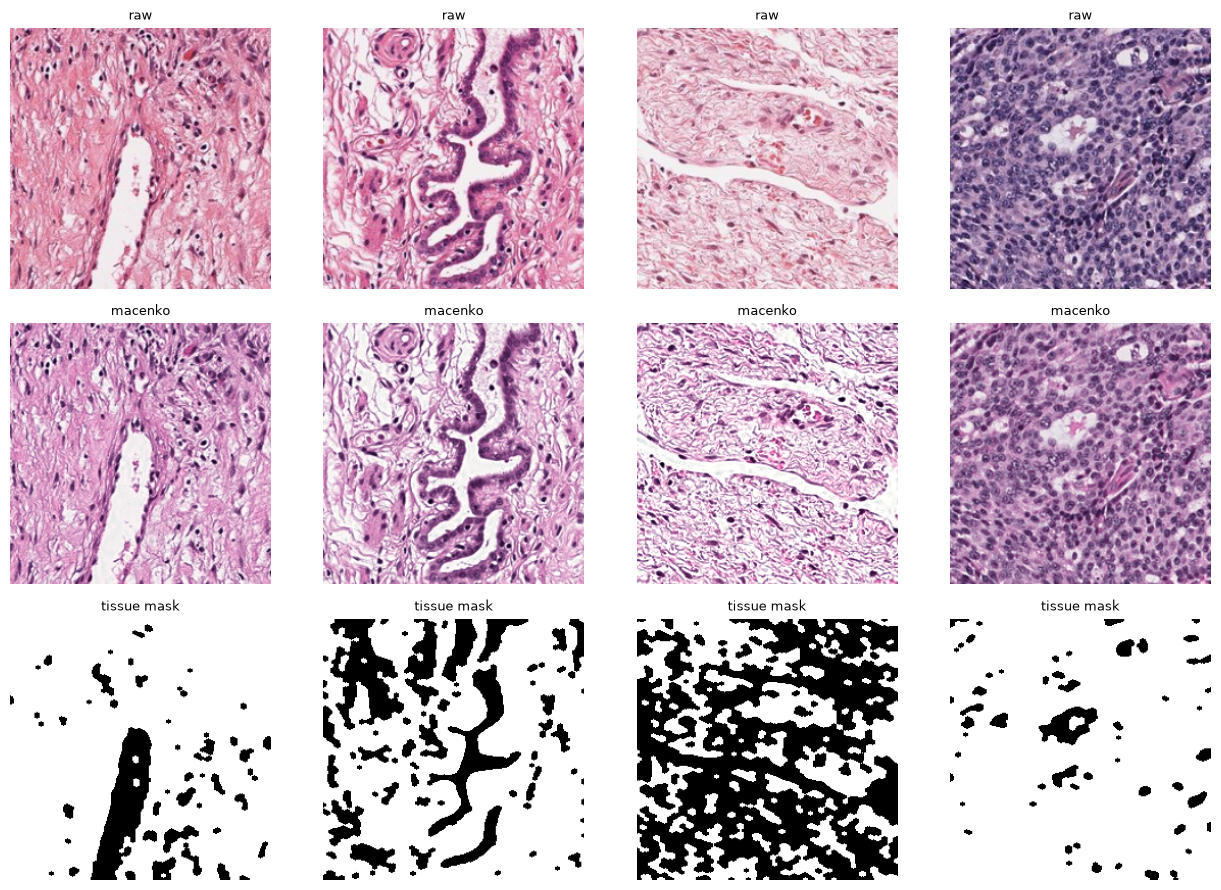

In [12]:
# QC: raw vs stain-normalised patches, and tissue mask
sample = items[items.kind == "patch"].sample(min(4, (items.kind == "patch").sum()), random_state=0) if (items.kind == "patch").any() else None
if sample is not None and NORMALIZER is not None:
    fig, ax = plt.subplots(3, len(sample), figsize=(3.2 * len(sample), 9), squeeze=False)
    for j, p in enumerate(sample.path):
        raw = read_rgb(p); raw = cv2.resize(raw, (IMG_SIZE, IMG_SIZE))
        nrm, _ = NORMALIZER.transform(raw)
        ax[0, j].imshow(raw); ax[1, j].imshow(nrm); ax[2, j].imshow(detect_tissue_mask(raw), cmap="gray")
        for i, t in enumerate(["raw", f"{CFG.STAIN_NORM}", "tissue mask"]): ax[i, j].set_title(t, fontsize=9); ax[i, j].axis("off")
    plt.tight_layout(); plt.savefig(OUT / "figs" / "preprocessing_qc.png", dpi=120); plt.show()

## 5. Augmentation, datasets & imbalance handling
Training augmentation: flips, 90° rotations, **HED colour jitter**, mild Gaussian blur, random crops (resized back to the model input). Validation / test: none. Both end with ImageNet mean/std normalisation.
Imbalance: inverse-frequency **class weights** in the loss (plus optional focal loss) — computed from the *training fold only*.

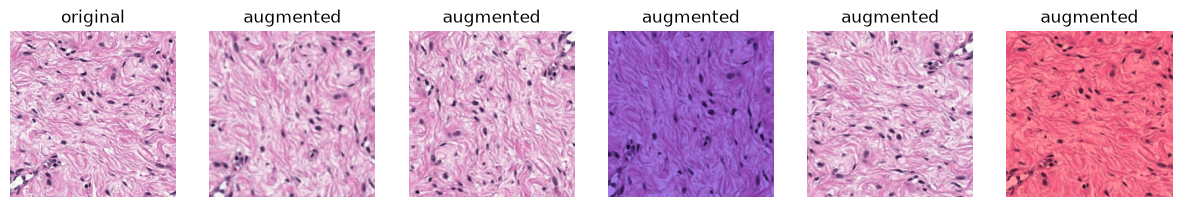

In [13]:
from skimage.color import rgb2hed, hed2rgb

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class HEDJitter:
    """Perturb haematoxylin/eosin/DAB channels: hed' = alpha*hed + beta, alpha~U(1-t,1+t), beta~U(-t,t)."""
    def __init__(self, theta=0.05, p=0.5): self.theta, self.p = theta, p
    def __call__(self, img):
        if random.random() > self.p: return img
        hed = rgb2hed(np.asarray(img))
        a = np.random.uniform(1 - self.theta, 1 + self.theta, (1, 1, 3))
        b = np.random.uniform(-self.theta, self.theta, (1, 1, 3))
        rgb = hed2rgb(hed * a + b)
        return Image.fromarray((np.clip(rgb, 0, 1) * 255).astype(np.uint8))

class RandomRotate90:
    OPS = [None, Image.ROTATE_90, Image.ROTATE_180, Image.ROTATE_270]
    def __call__(self, img):
        op = random.choice(self.OPS)
        return img if op is None else img.transpose(op)

def build_transform(size, train):
    norm = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    if not train:
        return transforms.Compose([transforms.Resize((size, size))] + norm)
    return transforms.Compose([
        transforms.RandomResizedCrop(size, scale=CFG.CROP_SCALE, ratio=(0.9, 1.1)),      # random crop
        transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),              # flips
        RandomRotate90(),                                                                # 90-degree rotations
        HEDJitter(CFG.HED_THETA, p=0.5),                                                 # HED colour jitter
        transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 1.0))], p=CFG.BLUR_P),   # mild blur
    ] + norm)

class PatchDataset(Dataset):
    def __init__(self, df, size, train):
        self.paths, self.labels = df.img_path.tolist(), df.label.astype(int).tolist()
        self.tf = build_transform(size, train)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

def make_loader(df, train, batch_size=None, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    nw = CFG.NUM_WORKERS
    return DataLoader(PatchDataset(df, IMG_SIZE, train), batch_size=batch_size or CFG.BATCH_SIZE * (1 if train else 2),
                      shuffle=train, drop_last=False, num_workers=nw, pin_memory=DEVICE.type == "cuda",
                      persistent_workers=False, generator=g,
                      worker_init_fn=lambda w: (np.random.seed(seed + w), random.seed(seed + w)))

# ---------- loss: class-weighted CE or focal ----------
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None):
        super().__init__(); self.gamma, self.weight = gamma, weight
    def forward(self, logits, y):
        ce = F.cross_entropy(logits, y, weight=self.weight, reduction="none")
        pt = torch.exp(-F.cross_entropy(logits, y, reduction="none"))
        return (((1 - pt) ** self.gamma) * ce).mean()

def class_weights(labels, n_classes):
    cnt = np.bincount(labels, minlength=n_classes).astype(np.float64); cnt[cnt == 0] = 1
    return torch.tensor(cnt.sum() / (n_classes * cnt), dtype=torch.float32)

def build_loss(train_labels):
    w = class_weights(np.asarray(train_labels), NUM_CLASSES).to(DEVICE)
    if CFG.LOSS == "focal":
        return FocalLoss(CFG.FOCAL_GAMMA, w)
    return nn.CrossEntropyLoss(weight=w, label_smoothing=CFG.LABEL_SMOOTHING)

# quick visual check of the augmentations
_tf, _im = build_transform(IMG_SIZE, True), Image.open(dev_df.img_path.iloc[0]).convert("RGB")
fig, ax = plt.subplots(1, 6, figsize=(15, 2.8))
ax[0].imshow(_im); ax[0].set_title("original")
for i in range(1, 6):
    t = _tf(_im).numpy().transpose(1, 2, 0) * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    ax[i].imshow(np.clip(t, 0, 1)); ax[i].set_title("augmented")
for a in ax: a.axis("off")
plt.savefig(OUT / "figs" / "augmentations.png", dpi=110, bbox_inches="tight"); plt.show()

## 6. Models: EfficientNet-B4 + CBAM (and ablation backbones)
`CNNClassifier` = pretrained backbone → **CBAM** (channel + spatial attention) → global pool → dropout → linear head.
It exposes `embed()` (the **1792-d** B4 embedding used by MIL) and `.features` (last conv block, the Grad-CAM target).
`use_cbam=False` and other backbones (ResNet-50) give the ablation models used for the Friedman/Nemenyi comparison.

In [14]:
class ChannelAttention(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(c, max(c // r, 4), 1, bias=False), nn.ReLU(inplace=False),
                                 nn.Conv2d(max(c // r, 4), c, 1, bias=False))
    def forward(self, x):
        return torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))

class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__(); self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        return torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))

class CBAM(nn.Module):
    def __init__(self, c, r=16, k=7):
        super().__init__(); self.ca, self.sa = ChannelAttention(c, r), SpatialAttention(k)
    def forward(self, x):
        x = x * self.ca(x)
        return x * self.sa(x)

def _load_backbone(name, pretrained):
    try:
        if name.startswith("effnet_b4"):
            m = efficientnet_b4(weights=EfficientNet_B4_Weights.IMAGENET1K_V1 if pretrained else None)
            return m.features, 1792
        if name.startswith("resnet50"):
            m = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
            return nn.Sequential(*list(m.children())[:-2]), 2048
        if name.startswith("densenet121"):
            m = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None)
            return nn.Sequential(m.features, nn.ReLU(inplace=False)), 1024
    except Exception as e:
        print(f"  [warn] could not load pretrained weights for {name} ({type(e).__name__}); using random init.")
        return _load_backbone(name, False)
    raise ValueError(name)

class CNNClassifier(nn.Module):
    def __init__(self, name, num_classes, pretrained=True, dropout=0.4):
        super().__init__()
        self.name = name
        self.features, self.feat_dim = _load_backbone(name, pretrained)
        self.cbam = CBAM(self.feat_dim) if name.endswith("_cbam") else nn.Identity()
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(self.feat_dim, num_classes))
    def embed(self, x):                                   # (B, feat_dim) e.g. 1792-d for B4
        return F.adaptive_avg_pool2d(self.cbam(self.features(x)), 1).flatten(1)
    def forward(self, x):
        return self.classifier(self.embed(x))
    def blocks(self):                                     # input -> output ordered list of modules for LLRD
        return list(self.features.children())

def freeze_backbone(m, freeze=True):
    for p in m.features.parameters(): p.requires_grad = not freeze

_t = CNNClassifier(CFG.MODEL_MAIN, NUM_CLASSES, pretrained=False)
print(f"{CFG.MODEL_MAIN}: {sum(p.numel() for p in _t.parameters())/1e6:.1f} M params | embedding dim = {_t.feat_dim} | "
      f"{len(_t.blocks())} backbone blocks"); del _t

effnet_b4_cbam: 18.0 M params | embedding dim = 1792 | 9 backbone blocks


## 7. Training — two stages, LLRD, AdamW + cosine, AMP, early stopping
**Stage A (warm-up):** backbone frozen (BatchNorm kept in eval mode so its statistics are not disturbed), train CBAM + head at lr ≈ 1e-3.
**Stage B (fine-tune):** unfreeze everything; head/CBAM lr = `HEAD_LR`, each backbone block towards the input gets ×`LLRD` (0.85) the lr of the block after it. Cosine schedule, early stopping on validation loss (patience = `EARLY_STOP_PATIENCE`).
The external set is never touched here.

In [15]:

# ============================================================
# TRAINING FUNCTIONS WITH LIVE PROGRESS LOGGING
# ============================================================

import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import gc

# ------------------------------------------------------------
# Timestamped logging
# ------------------------------------------------------------

def log(msg):
    print(
        f"[{time.strftime('%H:%M:%S')}] {msg}",
        flush=True
    )


# ------------------------------------------------------------
# Layer-wise learning rate decay optimizer
# ------------------------------------------------------------

def build_llrd_optimizer(model, cfg):

    log("Building LLRD optimizer...")

    groups = [{
        "params": (
            list(model.classifier.parameters())
            + list(model.cbam.parameters())
        ),
        "lr": cfg.HEAD_LR
    }]

    for i, blk in enumerate(reversed(model.blocks())):
        groups.append({
            "params": list(blk.parameters()),
            "lr": cfg.HEAD_LR * cfg.LLRD ** (i + 1)
        })

    groups = [g for g in groups if len(g["params"])]

    optimizer = torch.optim.AdamW(
        groups,
        weight_decay=cfg.WEIGHT_DECAY
    )

    log(f"LLRD optimizer ready: {len(groups)} parameter groups")

    return optimizer


# ------------------------------------------------------------
# Mixed precision
# ------------------------------------------------------------

USE_AMP = CFG.AMP and DEVICE.type == "cuda"

def _autocast():
    return torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=USE_AMP
    )


log(f"Device: {DEVICE}")
log(f"Mixed precision enabled: {USE_AMP}")

if DEVICE.type == "cuda":
    log(f"GPU: {torch.cuda.get_device_name(0)}")


# ------------------------------------------------------------
# One training or validation epoch
# ------------------------------------------------------------

def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None,
    freeze_bn=False,
    desc="epoch"
):

    train = optimizer is not None

    model.train(train)

    if train and freeze_bn:
        model.features.eval()

    tot, n, P, Y = 0.0, 0, [], []

    total_batches = len(loader)
    start_time = time.time()

    log("=" * 65)
    log(f"{desc} | {'TRAINING' if train else 'VALIDATION'} STARTED")
    log(f"Total batches: {total_batches}")
    log(f"Batch size: {loader.batch_size}")

    if train:
        log("Gradient computation: ON")
    else:
        log("Gradient computation: OFF")

    with torch.set_grad_enabled(train):

        for batch_idx, (x, y) in enumerate(loader, start=1):

            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            # Forward pass
            with _autocast():
                logits = model(x)

            loss = criterion(logits.float(), y)

            # Backpropagation and optimizer step
            if train:

                optimizer.zero_grad(set_to_none=True)

                scaler.scale(loss).backward()

                if CFG.GRAD_CLIP:
                    scaler.unscale_(optimizer)

                    nn.utils.clip_grad_norm_(
                        model.parameters(),
                        CFG.GRAD_CLIP
                    )

                scaler.step(optimizer)
                scaler.update()

            # Accumulate metrics
            tot += loss.item() * len(y)
            n += len(y)

            P.append(
                torch.softmax(logits.float(), 1)
                .detach()
                .cpu()
                .numpy()
            )

            Y.append(y.cpu().numpy())

            # ------------------------------------------------
            # LIVE PROGRESS: every 10 batches + final batch
            # ------------------------------------------------

            if batch_idx % 10 == 0 or batch_idx == total_batches:

                elapsed = time.time() - start_time

                speed = n / max(elapsed, 1e-6)

                avg_loss = tot / max(n, 1)

                progress = 100 * batch_idx / max(total_batches, 1)

                msg = (
                    f"{desc} | "
                    f"Batch {batch_idx}/{total_batches} "
                    f"({progress:.1f}%) | "
                    f"Loss={avg_loss:.4f} | "
                    f"Samples={n:,} | "
                    f"Speed={speed:.1f} patches/sec | "
                    f"Elapsed={elapsed/60:.2f} min"
                )

                if DEVICE.type == "cuda":

                    allocated = (
                        torch.cuda.memory_allocated() / 1024**3
                    )

                    reserved = (
                        torch.cuda.memory_reserved() / 1024**3
                    )

                    msg += (
                        f" | GPU allocated={allocated:.2f} GB"
                        f" | GPU reserved={reserved:.2f} GB"
                    )

                log(msg)

    elapsed = time.time() - start_time

    avg_loss = tot / max(n, 1)

    log(
        f"{desc} COMPLETE | "
        f"Loss={avg_loss:.4f} | "
        f"Samples={n:,} | "
        f"Time={elapsed/60:.2f} min"
    )

    return (
        avg_loss,
        np.concatenate(Y),
        np.concatenate(P)
    )


# ------------------------------------------------------------
# Prediction / embedding extraction
# ------------------------------------------------------------

@torch.no_grad()
def predict(model, df, return_embeddings=False, batch_size=None):

    start_time = time.time()

    log(
        f"Prediction started | "
        f"Patches={len(df):,} | "
        f"Embeddings={return_embeddings}"
    )

    model.eval()

    loader = make_loader(df, False, batch_size)

    P, E = [], []

    total_batches = len(loader)

    for batch_idx, (x, _) in enumerate(loader, start=1):

        x = x.to(DEVICE, non_blocking=True)

        with _autocast():
            e = model.embed(x)
            logits = model.classifier(e)

        P.append(
            torch.softmax(logits.float(), 1)
            .cpu()
            .numpy()
        )

        if return_embeddings:
            E.append(e.float().cpu().numpy())

        if batch_idx % 10 == 0 or batch_idx == total_batches:

            elapsed = time.time() - start_time

            log(
                f"Prediction progress: "
                f"{batch_idx}/{total_batches} batches "
                f"({100*batch_idx/max(total_batches,1):.1f}%) | "
                f"Elapsed={elapsed/60:.2f} min"
            )

    P = np.concatenate(P)

    log(
        f"Prediction COMPLETE | "
        f"Output shape={P.shape} | "
        f"Time={(time.time()-start_time)/60:.2f} min"
    )

    if return_embeddings:
        E = np.concatenate(E)

        log(f"Embedding shape: {E.shape}")

        return P, E

    return P


# ------------------------------------------------------------
# CNN training: Stage A + Stage B
# ------------------------------------------------------------

def train_cnn(model_name, tr_df, va_df, seed, tag):

    total_start = time.time()

    log("=" * 70)
    log(f"TRAIN_CNN STARTED: {tag}")
    log(f"Model: {model_name} | Seed: {seed}")
    log(f"Training patches: {len(tr_df):,}")
    log(f"Validation patches: {len(va_df):,}")
    log(f"Device: {DEVICE}")
    log(f"AMP: {USE_AMP}")
    log("=" * 70)

    # --------------------------------------------------------
    # Model initialization
    # --------------------------------------------------------

    log(f"[{tag}] Setting random seed...")

    set_seed(seed)

    log(f"[{tag}] Initializing CNN model...")

    model = CNNClassifier(
        model_name,
        NUM_CLASSES,
        CFG.PRETRAINED,
        CFG.DROPOUT
    ).to(DEVICE)

    log(
        f"[{tag}] Model initialized | "
        f"Feature dimension={model.feat_dim}"
    )

    # --------------------------------------------------------
    # Loss, DataLoaders, GradScaler
    # --------------------------------------------------------

    log(f"[{tag}] Building loss function...")

    crit = build_loss(tr_df.label.values)

    log(f"[{tag}] Creating training DataLoader...")

    tr_loader = make_loader(
        tr_df,
        True,
        seed=seed
    )

    log(f"[{tag}] Creating validation DataLoader...")

    va_loader = make_loader(
        va_df,
        False
    )

    log(
        f"[{tag}] DataLoaders ready | "
        f"Train batches={len(tr_loader)} | "
        f"Validation batches={len(va_loader)}"
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    hist = []
    best = float("inf")
    best_state = None
    bad = 0

    # ========================================================
    # STAGE A: WARM-UP (FROZEN BACKBONE)
    # ========================================================

    log("=" * 70)
    log(
        f"[{tag}] STAGE A: WARM-UP STARTED | "
        f"Epochs={CFG.WARMUP_EPOCHS}"
    )
    log("=" * 70)

    freeze_backbone(model, True)

    log(f"[{tag}] Backbone frozen.")

    optA = torch.optim.AdamW(
        [
            p for p in model.parameters()
            if p.requires_grad
        ],
        lr=CFG.WARMUP_LR,
        weight_decay=CFG.WEIGHT_DECAY
    )

    log(
        f"[{tag}] Warm-up optimizer ready | "
        f"LR={CFG.WARMUP_LR}"
    )

    for ep in range(CFG.WARMUP_EPOCHS):

        epoch_start = time.time()

        log(
            f"[{tag}] STAGE A EPOCH "
            f"{ep+1}/{CFG.WARMUP_EPOCHS} STARTED"
        )

        # Training
        trl, _, _ = run_epoch(
            model,
            tr_loader,
            crit,
            optA,
            scaler,
            freeze_bn=True,
            desc=(
                f"{tag} | Stage A | "
                f"Epoch {ep+1}/{CFG.WARMUP_EPOCHS}"
            )
        )

        # Validation
        vl, yv, pv = run_epoch(
            model,
            va_loader,
            crit,
            desc=(
                f"{tag} | Stage A | "
                f"Validation {ep+1}/{CFG.WARMUP_EPOCHS}"
            )
        )

        val_acc = accuracy_score(
            yv,
            pv.argmax(1)
        )

        hist.append(
            dict(
                stage="A",
                epoch=ep+1,
                train_loss=trl,
                val_loss=vl,
                val_acc=val_acc
            )
        )

        log(
            f"[{tag}] STAGE A EPOCH "
            f"{ep+1}/{CFG.WARMUP_EPOCHS} COMPLETE | "
            f"Train loss={trl:.4f} | "
            f"Val loss={vl:.4f} | "
            f"Val accuracy={val_acc:.3f} | "
            f"Epoch time={(time.time()-epoch_start)/60:.2f} min"
        )

    log(f"[{tag}] STAGE A COMPLETE.")

    # ========================================================
    # STAGE B: FINE-TUNING
    # ========================================================

    log("=" * 70)
    log(
        f"[{tag}] STAGE B: FINE-TUNING STARTED | "
        f"Epochs={CFG.FINETUNE_EPOCHS}"
    )
    log("=" * 70)

    log(f"[{tag}] Unfreezing backbone...")

    freeze_backbone(model, False)

    log(f"[{tag}] Backbone unfrozen.")

    optB = build_llrd_optimizer(
        model,
        CFG
    )

    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        optB,
        T_max=CFG.FINETUNE_EPOCHS
    )

    log(f"[{tag}] Cosine learning rate scheduler ready.")

    for ep in range(CFG.FINETUNE_EPOCHS):

        epoch_start = time.time()

        log(
            f"[{tag}] STAGE B EPOCH "
            f"{ep+1}/{CFG.FINETUNE_EPOCHS} STARTED"
        )

        # Training
        trl, _, _ = run_epoch(
            model,
            tr_loader,
            crit,
            optB,
            scaler,
            desc=(
                f"{tag} | Stage B | "
                f"Epoch {ep+1}/{CFG.FINETUNE_EPOCHS}"
            )
        )

        # Validation
        vl, yv, pv = run_epoch(
            model,
            va_loader,
            crit,
            desc=(
                f"{tag} | Stage B | "
                f"Validation {ep+1}/{CFG.FINETUNE_EPOCHS}"
            )
        )

        sched.step()

        val_acc = accuracy_score(
            yv,
            pv.argmax(1)
        )

        hist.append(
            dict(
                stage="B",
                epoch=ep+1,
                train_loss=trl,
                val_loss=vl,
                val_acc=val_acc
            )
        )

        log(
            f"[{tag}] STAGE B EPOCH "
            f"{ep+1}/{CFG.FINETUNE_EPOCHS} COMPLETE | "
            f"Train loss={trl:.4f} | "
            f"Val loss={vl:.4f} | "
            f"Val accuracy={val_acc:.3f} | "
            f"Epoch time={(time.time()-epoch_start)/60:.2f} min"
        )

        # ----------------------------------------------------
        # Early stopping / best checkpoint in memory
        # ----------------------------------------------------

        if vl < best - 1e-4:

            best = vl
            bad = 0

            log(
                f"[{tag}] New best validation loss: {best:.4f}"
            )

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            log(f"[{tag}] Best model state updated in memory.")

        else:

            bad += 1

            log(
                f"[{tag}] No improvement | "
                f"Early stopping counter: "
                f"{bad}/{CFG.EARLY_STOP_PATIENCE}"
            )

            if bad >= CFG.EARLY_STOP_PATIENCE:

                log(
                    f"[{tag}] EARLY STOPPING at "
                    f"fine-tuning epoch {ep+1}"
                )

                break

    # --------------------------------------------------------
    # Restore best model
    # --------------------------------------------------------

    if best_state is not None:

        log(f"[{tag}] Restoring best model weights...")

        model.load_state_dict(best_state)

        log(f"[{tag}] Best model weights restored.")

    else:
        log(
            f"[{tag}] No best state saved; "
            f"keeping final model weights."
        )

    # --------------------------------------------------------
    # Finished
    # --------------------------------------------------------

    total_time = (time.time() - total_start) / 60

    log("=" * 70)
    log(f"[{tag}] CNN TRAINING COMPLETE")
    log(f"[{tag}] Total training time: {total_time:.2f} min")
    log(f"[{tag}] Epochs completed: {len(hist)}")
    log("=" * 70)

    return model, pd.DataFrame(hist)

[22:23:59] Device: cuda
[22:23:59] Mixed precision enabled: True
[22:23:59] GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 8. Slide-level aggregation — gated ABMIL on 1792-d B4 embeddings
For every slide (a "bag" of patches) the fine-tuned B4-CBAM encoder produces one **1792-d embedding per patch**. A **gated attention-MIL** head (Ilse et al., 2018) learns a per-patch attention weight, pools the bag, and outputs a slide-level subtype prediction. The attention weights are kept for the heat-maps in §12.
The encoder is frozen for MIL training and always belongs to the same CV fold, so validation/external slides never influence their own encoder. A simple **mean-probability** aggregation is kept as a baseline.

In [16]:
class GatedABMIL(nn.Module):
    def __init__(self, in_dim=1792, hidden=256, n_classes=5, dropout=0.25):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        self.V = nn.Sequential(nn.Linear(in_dim, hidden), nn.Tanh())
        self.U = nn.Sequential(nn.Linear(in_dim, hidden), nn.Sigmoid())
        self.w = nn.Linear(hidden, 1)
        self.cls = nn.Linear(in_dim, n_classes)
    def forward(self, h):                                 # h: (N, in_dim) -> logits (1, C), attention (N,)
        h = self.drop(h)
        a = torch.softmax(self.w(self.V(h) * self.U(h)).squeeze(-1), 0)
        return self.cls((a[:, None] * h).sum(0, keepdim=True)), a

def make_bags(df, emb):
    """df rows align with emb rows. Returns {slide_id: dict(h, y, idx)} (idx = row positions in df)."""
    bags = {}
    for sid, g in df.groupby("slide_id", sort=False):
        idx = g.index.to_numpy()
        bags[sid] = dict(h=torch.tensor(emb[idx], dtype=torch.float32), y=int(g.label.mode().iloc[0]), idx=idx)
    return bags

def mil_forward_all(mil, bags, train=False, max_bag=None, opt=None, crit=None, accum=8):
    mil.train(train); tot, P, Y, A = 0.0, [], [], {}
    keys = list(bags)
    if train: random.shuffle(keys)
    if train: opt.zero_grad()
    with torch.set_grad_enabled(train):
        for i, k in enumerate(keys):
            h = bags[k]["h"]
            if train and max_bag and len(h) > max_bag: h = h[torch.randperm(len(h))[:max_bag]]
            logits, a = mil(h.to(DEVICE))
            y = torch.tensor([bags[k]["y"]], device=DEVICE)
            loss = crit(logits, y) if crit is not None else torch.zeros((), device=DEVICE)
            if train:
                (loss / accum).backward()
                if (i + 1) % accum == 0 or i == len(keys) - 1: opt.step(); opt.zero_grad()
            tot += loss.item(); P.append(torch.softmax(logits, 1).detach().cpu().numpy()[0]); Y.append(bags[k]["y"])
            A[k] = a.detach().cpu().numpy()
    return tot / max(len(keys), 1), keys, np.array(Y), np.array(P), A

def train_abmil(train_bags, val_bags, in_dim, seed, tag):
    set_seed(seed)
    mil = GatedABMIL(in_dim, CFG.MIL_HIDDEN, NUM_CLASSES).to(DEVICE)
    ylab = np.array([b["y"] for b in train_bags.values()])
    crit = build_loss(ylab)
    opt = torch.optim.AdamW(mil.parameters(), lr=CFG.MIL_LR, weight_decay=CFG.WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.MIL_EPOCHS)
    best, best_state, bad, hist = float("inf"), None, 0, []
    for ep in range(CFG.MIL_EPOCHS):
        trl, *_ = mil_forward_all(mil, train_bags, True, CFG.MIL_MAX_BAG, opt, crit)
        vl, _, yv, pv, _ = mil_forward_all(mil, val_bags, False, crit=crit); sched.step()
        hist.append(dict(epoch=ep + 1, train_loss=trl, val_loss=vl, val_acc=accuracy_score(yv, pv.argmax(1))))
        if vl < best - 1e-4:
            best, bad, best_state = vl, 0, {k: v.detach().cpu().clone() for k, v in mil.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG.MIL_PATIENCE: break
    print(f"[{tag}] ABMIL trained {len(hist)} epochs, best val loss {best:.4f}")
    if best_state: mil.load_state_dict(best_state)
    return mil, pd.DataFrame(hist)

def slide_table(df):
    """slide-level ground truth + majority label (used to align mean-aggregation with MIL)."""
    return df.groupby("slide_id", sort=False).agg(label=("label", lambda s: int(s.mode().iloc[0])),
                                                  patient_id=("patient_id", "first")).reset_index()

def mean_aggregate(df, probs):
    g = pd.DataFrame(probs, index=df.index).groupby(df.slide_id.values, sort=False).mean()
    st = slide_table(df).set_index("slide_id").loc[g.index]
    return st.label.values, g.values, st.patient_id.values, g.index.to_numpy()

## 9. Evaluation toolkit
* **Metrics**: accuracy, AUC (one-vs-rest macro; binary uses the positive class), sensitivity & specificity (macro + per class), F1 (macro), **MCC**, balanced accuracy, confusion matrix.
* **95 % CIs**: *cluster bootstrap* — patients (not patches) are resampled, so the intervals are not artificially narrow.
* **DeLong** test (fast Sun–Xu implementation, one-vs-rest per class) for comparing correlated AUCs.
* **Friedman + Nemenyi** across folds×seeds for ≥ 3 models, with a critical-difference plot.

In [17]:
METRICS = ["accuracy", "auc", "sensitivity", "specificity", "f1", "mcc", "balanced_acc"]

def per_class_sens_spec(y, pred, n):
    cm = confusion_matrix(y, pred, labels=range(n)); tot = cm.sum()
    sens, spec = np.full(n, np.nan), np.full(n, np.nan)
    for c in range(n):
        tp, fn = cm[c, c], cm[c].sum() - cm[c, c]; fp = cm[:, c].sum() - tp; tn = tot - tp - fn - fp
        if tp + fn: sens[c] = tp / (tp + fn)
        if tn + fp: spec[c] = tn / (tn + fp)
    return sens, spec, cm

def compute_metrics(y, probs, n=None):
    n = n or probs.shape[1]; y = np.asarray(y); pred = probs.argmax(1)
    present = np.unique(y)
    sens, spec, cm = per_class_sens_spec(y, pred, n)
    try:
        if len(present) < 2: auc = np.nan
        elif n == 2: auc = roc_auc_score(y, probs[:, 1])
        else:
            aucs = [roc_auc_score((y == c).astype(int), probs[:, c]) for c in present if 0 < (y == c).sum() < len(y)]
            auc = float(np.mean(aucs))
    except ValueError:
        auc = np.nan
    return dict(accuracy=accuracy_score(y, pred), auc=auc, sensitivity=np.nanmean(sens[present]),
                specificity=np.nanmean(spec[present]), f1=f1_score(y, pred, average="macro", labels=present, zero_division=0),
                mcc=matthews_corrcoef(y, pred), balanced_acc=balanced_accuracy_score(y, pred))

def cluster_bootstrap_ci(y, probs, groups, n_boot=500, seed=0, metrics=METRICS):
    rng = np.random.RandomState(seed); y, groups = np.asarray(y), np.asarray(groups)
    ug = np.unique(groups); idx_by = {g: np.where(groups == g)[0] for g in ug}
    out = {m: [] for m in metrics}
    for _ in range(n_boot):
        idx = np.concatenate([idx_by[g] for g in rng.choice(ug, len(ug), replace=True)])
        mm = compute_metrics(y[idx], probs[idx], probs.shape[1])
        for m in metrics: out[m].append(mm[m])
    return {m: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) if np.isfinite(v).any() else (np.nan, np.nan) for m, v in out.items()}

def fmt_ci(v, ci): return f"{v:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]"
def fmt_ms(x):
    x = np.asarray(x, float); return f"{np.nanmean(x):.3f} ± {np.nanstd(x, ddof=1) if np.isfinite(x).sum() > 1 else 0:.3f}"

# ---------------- DeLong ----------------
def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1); i = j
    T2 = np.empty(N); T2[J] = T + 1; return T2

def _fast_delong(preds, m):
    n = preds.shape[1] - m; k = preds.shape[0]
    pos, neg = preds[:, :m], preds[:, m:]
    tx, ty, tz = np.empty((k, m)), np.empty((k, n)), np.empty((k, m + n))
    for r in range(k):
        tx[r], ty[r], tz[r] = _midrank(pos[r]), _midrank(neg[r]), _midrank(preds[r])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01, v10 = (tz[:, :m] - tx) / n, 1.0 - (tz[:, m:] - ty) / m
    cov = np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
    return aucs, cov

def delong_test(y_bin, p1, p2):
    """Two correlated ROC curves on the same samples. Returns dict(auc1, auc2, z, p, ci1, ci2)."""
    y_bin = np.asarray(y_bin).astype(int); order = np.argsort(-y_bin, kind="stable")
    m = int(y_bin.sum())
    if m == 0 or m == len(y_bin): return dict(auc1=np.nan, auc2=np.nan, z=np.nan, p=np.nan, ci1=(np.nan,) * 2, ci2=(np.nan,) * 2)
    preds = np.vstack([np.asarray(p1)[order], np.asarray(p2)[order]])
    aucs, cov = _fast_delong(preds, m)
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var) if var > 1e-16 else 0.0
    ci = lambda a, v: (max(0, a - 1.96 * np.sqrt(v)), min(1, a + 1.96 * np.sqrt(v)))
    return dict(auc1=aucs[0], auc2=aucs[1], z=z, p=2 * stats.norm.sf(abs(z)), ci1=ci(aucs[0], cov[0, 0]), ci2=ci(aucs[1], cov[1, 1]))

def delong_ovr_table(y, P1, P2, classes, name1, name2):
    rows = []
    for c, cn in enumerate(classes):
        r = delong_test((np.asarray(y) == c).astype(int), P1[:, c], P2[:, c])
        rows.append({"class": cn, f"AUC {name1}": fmt_ci(r["auc1"], r["ci1"]), f"AUC {name2}": fmt_ci(r["auc2"], r["ci2"]),
                     "z": r["z"], "p (DeLong)": r["p"]})
    return pd.DataFrame(rows)

# ---------------- Friedman / Nemenyi ----------------
def friedman_nemenyi(score_df, alpha=0.05):
    """score_df: rows = blocks (fold x seed), columns = models, higher = better."""
    sd = score_df.dropna(); N, k = sd.shape
    ranks = sd.rank(axis=1, ascending=False).mean(0)
    out = {"n_blocks": N, "k_models": k, "avg_rank": ranks}
    if k >= 3 and N >= 2:
        stat, p = stats.friedmanchisquare(*[sd[c].values for c in sd.columns]); out.update(chi2=stat, p=p)
    else:
        out.update(chi2=np.nan, p=np.nan)
    se = np.sqrt(k * (k + 1) / (12.0 * N))
    q_crit = stats.studentized_range.ppf(1 - alpha, k, np.inf) if k >= 2 else np.nan
    out["CD"] = q_crit * se
    pm = pd.DataFrame(np.nan, index=sd.columns, columns=sd.columns)
    for a in sd.columns:
        for b in sd.columns:
            pm.loc[a, b] = 1.0 if a == b else float(stats.studentized_range.sf(abs(ranks[a] - ranks[b]) / se, k, np.inf))
    out["nemenyi_p"] = pm
    return out

def cd_plot(res, title, path=None):
    r = res["avg_rank"].sort_values(); fig, ax = plt.subplots(figsize=(7, 1.8 + 0.3 * len(r)))
    ax.hlines(0, 1, len(r) + 0.5, color="k"); 
    for i, (n_, v) in enumerate(r.items()):
        ax.plot(v, 0, "o"); ax.text(v, 0.12 * (1 if i % 2 else -1) - (0.05 if i % 2 == 0 else 0), f"{n_}\n({v:.2f})", ha="center", fontsize=8)
    ax.hlines(0.6, r.min(), r.min() + res["CD"], color="r", lw=3); ax.text(r.min(), 0.68, f"CD = {res['CD']:.2f}", color="r", fontsize=8)
    ax.set_ylim(-0.7, 1); ax.set_yticks([]); ax.set_xlabel("average rank (1 = best)"); ax.set_title(title, fontsize=10)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=130)
    plt.show()

# self-test of the statistics on synthetic scores (should print sensible numbers)
_rng = np.random.RandomState(0); _y = _rng.randint(0, 2, 400)
_a, _b = _y * 0.8 + _rng.randn(400) * 0.5, _y * 0.4 + _rng.randn(400) * 0.5
_d = delong_test(_y, _a, _b); print(f"DeLong self-test: AUC {_d['auc1']:.3f} vs {_d['auc2']:.3f}, z={_d['z']:.2f}, p={_d['p']:.2g}")
_s = pd.DataFrame({"A": _rng.rand(10) + .3, "B": _rng.rand(10) + .1, "C": _rng.rand(10)}); _f = friedman_nemenyi(_s)
print(f"Friedman self-test: chi2={_f['chi2']:.2f}, p={_f['p']:.3g}, CD={_f['CD']:.2f}")

DeLong self-test: AUC 0.866 vs 0.736, z=4.15, p=3.4e-05
Friedman self-test: chi2=14.60, p=0.000676, CD=1.05


## 10. Run the experiments
`5 folds × several seeds` for the main model (**EfficientNet-B4 + CBAM**), plus fewer-seed ablations (B4 without CBAM, ResNet-50) so that Friedman/Nemenyi has ≥ 3 models to compare.
Every run: train on 4 folds → early-stop on the 5th → predict the held-out fold **and** the external set → extract 1792-d embeddings → train gated ABMIL. Results are cached in `outputs/runs/` so an interrupted session resumes where it stopped.

> Budget warning: 5 folds × 3 seeds × (5 + up to 40 epochs) is a lot of GPU time. Start with `CFG.FAST_DEV=True`, then reduce `SEEDS` / `RUN_FOLDS` / `FINETUNE_EPOCHS` to fit your budget (the pipeline is unchanged, only the reported ± SD gets less reliable).

In [ ]:

# ------- TRAINING RUNS WITH DETAILED PROGRESS LOGGING -------

import time
import gc
import pickle
import torch
import numpy as np
from pathlib import Path


def log(msg):
    """Print a timestamped message immediately."""
    now = time.strftime("%H:%M:%S")
    print(f"[{now}] {msg}", flush=True)


log("=" * 70)
log("INITIALISING TRAINING PIPELINE")
log("=" * 70)

# -------------------- Dataset / configuration --------------------

log("Creating PIDX from patch_df...")
PIDX = patch_df.set_index("pid")
log(f"PIDX ready: {len(PIDX)} patches")

log("Setting run directory...")
RUN_DIR = OUT / "runs"
RUN_DIR.mkdir(parents=True, exist_ok=True)
log(f"Run directory: {RUN_DIR}")

log("Checking whether slide-level ABMIL can be used...")
median_patches = dev_df.groupby("slide_id").size().median()
MIL_OK = bool(CFG.RUN_MIL and median_patches >= 2)

log(
    f"Slide-level ABMIL enabled: {MIL_OK} | "
    f"median patches/slide: {median_patches}"
)

if CFG.RUN_MIL and not MIL_OK:
    log("ABMIL skipped: median patches per slide is below 2.")


def run_path(model, seed, fold, ext="pkl"):
    return RUN_DIR / f"{model}_s{seed}_f{fold}.{ext}"


# -------------------- One experiment --------------------

def run_experiment(model_name, seed, fold, with_mil,
                   run_idx=None, total_runs=None):

    run_label = (
        f"Run {run_idx}/{total_runs}"
        if run_idx is not None else "Experiment"
    )

    tag = f"{model_name}|seed{seed}|fold{fold}"

    log("-" * 70)
    log(f"{run_label} STARTED: {tag}")
    log(f"ABMIL requested: {with_mil} | ABMIL available: {MIL_OK}")

    pth = run_path(model_name, seed, fold)

    # ---------- Check cache ----------

    log(f"{run_label}: Checking for cached results: {pth.name}")

    if pth.exists():
        log(f"{run_label}: Cached result found. Loading pickle...")
        with open(pth, "rb") as f:
            cached_rec = pickle.load(f)

        log(f"{run_label}: Cached result loaded successfully.")
        return cached_rec

    log(f"{run_label}: No cached result found. Training required.")

    # ---------- Prepare train / validation splits ----------

    log(f"{run_label}: Preparing train and validation dataframes...")

    tr = dev_df[dev_df.fold != fold].reset_index(drop=True)
    va = dev_df[dev_df.fold == fold].reset_index(drop=True)

    log(
        f"{run_label}: Split ready | "
        f"train patches={len(tr):,} | "
        f"validation patches={len(va):,}"
    )

    t0 = time.time()

    # ---------- CNN training ----------

    log(f"{run_label}: Starting CNN training...")
    log(f"{run_label}: Model={model_name}, seed={seed}, fold={fold}")

    model, hist = train_cnn(
        model_name, tr, va, seed, tag
    )

    log(
        f"{run_label}: CNN training returned. "
        f"Elapsed time: {(time.time()-t0)/60:.2f} min"
    )

    # ---------- Save CNN checkpoint ----------

    pt_path = run_path(model_name, seed, fold, "pt")

    log(f"{run_label}: Saving CNN checkpoint to {pt_path.name}...")
    torch.save(model.state_dict(), pt_path)
    log(f"{run_label}: CNN checkpoint saved.")

    # ---------- Validation predictions ----------

    log(f"{run_label}: Generating validation predictions...")
    pv, ev = predict(model, va, True)
    log(f"{run_label}: Validation predictions complete. Shape={pv.shape}")

    rec = dict(
        model=model_name,
        seed=seed,
        fold=fold,
        hist=hist,
        val_pid=va.pid.values,
        val_probs=pv,
        feat_dim=model.feat_dim
    )

    # ---------- External test predictions ----------

    if len(ext_df):
        log(f"{run_label}: Generating external test predictions...")
        pe, ee = predict(model, ext_df, True)

        rec.update(
            ext_pid=ext_df.pid.values,
            ext_probs=pe
        )

        log(
            f"{run_label}: External predictions complete. "
            f"Shape={pe.shape}"
        )
    else:
        log(f"{run_label}: External dataset is empty. Skipping.")

    # ---------- ABMIL ----------

    if with_mil and MIL_OK:

        log(f"{run_label}: ABMIL requested and available.")

        log(f"{run_label}: Extracting CNN features for training patches...")
        _, etr = predict(model, tr, True)
        log(f"{run_label}: Training feature extraction complete.")

        log(f"{run_label}: Creating training and validation bags...")
        bags = {
            "train": make_bags(tr, etr),
            "val": make_bags(va, ev)
        }

        log(
            f"{run_label}: Bags created | "
            f"train slides={len(bags['train'])} | "
            f"validation slides={len(bags['val'])}"
        )

        if len(ext_df):
            log(f"{run_label}: Creating external test bags...")
            bags["ext"] = make_bags(ext_df, ee)
            log(f"{run_label}: External bags created.")

        log(f"{run_label}: Starting ABMIL training...")
        mil, mhist = train_abmil(
            bags["train"],
            bags["val"],
            model.feat_dim,
            seed,
            tag
        )

        log(f"{run_label}: ABMIL training returned.")

        # ABMIL predictions
        for split in ("val", "ext"):

            if split in bags:
                log(f"{run_label}: Generating ABMIL {split} predictions...")

                _, keys, y, P, A = mil_forward_all(
                    mil, bags[split]
                )

                rec[f"mil_{split}"] = dict(
                    slide_ids=np.array(keys),
                    y=y,
                    probs=P,
                    attn=A
                )

                log(
                    f"{run_label}: ABMIL {split} predictions complete. "
                    f"Slides={len(keys)}"
                )

        log(f"{run_label}: Saving ABMIL model state...")
        rec["mil_state"] = {
            k: v.cpu() for k, v in mil.state_dict().items()
        }
        rec["mil_hist"] = mhist

        log(f"{run_label}: ABMIL state saved in record.")

    elif with_mil:
        log(f"{run_label}: ABMIL requested but MIL_OK=False. Skipping.")
    else:
        log(f"{run_label}: ABMIL not requested for this run.")

    # ---------- Record elapsed time and save ----------

    rec["minutes"] = (time.time() - t0) / 60

    log(
        f"{run_label}: Saving experiment record to {pth.name}..."
    )

    with open(pth, "wb") as f:
        pickle.dump(rec, f)

    log(
        f"{run_label}: Experiment record saved successfully. "
        f"Total elapsed: {rec['minutes']:.2f} min"
    )

    # ---------- Cleanup ----------

    log(f"{run_label}: Releasing model memory...")
    del model
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        log(
            f"{run_label}: CUDA cache cleared. "
            f"Allocated GPU memory: "
            f"{torch.cuda.memory_allocated()/1024**3:.2f} GB"
        )

    log(f"{run_label}: FINISHED SUCCESSFULLY.")
    return rec


# -------------------- Build experiment plan --------------------

log("Building training plan...")

RUNS = {}

plan = [
    (CFG.MODEL_MAIN, s, f, True)
    for s in CFG.SEEDS
    for f in CFG.RUN_FOLDS
]

if CFG.RUN_ABLATIONS:
    plan += [
        (m, s, f, False)
        for m in CFG.ABLATION_MODELS
        for s in CFG.ABLATION_SEEDS
        for f in CFG.RUN_FOLDS
    ]

total_runs = len(plan)

log(f"{total_runs} training runs planned.")
log(f"Main model: {CFG.MODEL_MAIN}")
log(f"Seeds: {CFG.SEEDS}")
log(f"Folds: {CFG.RUN_FOLDS}")
log(f"Run ablations: {CFG.RUN_ABLATIONS}")
log(f"Device: {DEVICE}")

if DEVICE.type == "cuda":
    log(f"GPU: {torch.cuda.get_device_name(0)}")
    log(
        f"GPU memory allocated before runs: "
        f"{torch.cuda.memory_allocated()/1024**3:.2f} GB"
    )


# -------------------- Execute runs --------------------

overall_start = time.time()
completed = 0

log("=" * 70)
log("STARTING ALL TRAINING RUNS")
log("=" * 70)

for idx, (m, s, f, mil) in enumerate(plan, start=1):

    log(f"PROGRESS: {idx}/{total_runs} runs")
    log(f"Next run: model={m}, seed={s}, fold={f}, MIL={mil}")

    run_start = time.time()

    try:
        RUNS[(m, s, f)] = run_experiment(
            m, s, f, mil,
            run_idx=idx,
            total_runs=total_runs
        )

        completed += 1

        log(
            f"PROGRESS: {completed}/{total_runs} runs completed. "
            f"Last run took {(time.time()-run_start)/60:.2f} min. "
            f"Total elapsed: {(time.time()-overall_start)/60:.2f} min"
        )

    except Exception as e:
        log(f"ERROR in run {idx}/{total_runs}: {m}, seed={s}, fold={f}")
        log(f"Error type: {type(e).__name__}")
        log(f"Error message: {e}")
        log("Stopping the experiment loop. See traceback below.")
        raise

log("=" * 70)
log(f"ALL {completed}/{total_runs} RUNS FINISHED / LOADED.")
log(f"Total wall-clock time: {(time.time()-overall_start)/60:.2f} min")
log("=" * 70)

[22:23:59] ======================================================================
[22:23:59] INITIALISING TRAINING PIPELINE
[22:23:59] ======================================================================
[22:23:59] Creating PIDX from patch_df...
[22:23:59] PIDX ready: 29673 patches
[22:23:59] Setting run directory...
[22:23:59] Run directory: outputs\runs
[22:23:59] Checking whether slide-level ABMIL can be used...
[22:23:59] Slide-level ABMIL enabled: True | median patches/slide: 639.0
[22:23:59] Building training plan...
[22:23:59] 25 training runs planned.
[22:23:59] Main model: effnet_b4_cbam
[22:23:59] Seeds: [0, 1, 2]
[22:23:59] Folds: [0, 1, 2, 3, 4]
[22:23:59] Run ablations: True
[22:23:59] Device: cuda
[22:23:59] GPU: NVIDIA GeForce RTX 4060 Laptop GPU
[22:23:59] GPU memory allocated before runs: 0.00 GB
[22:23:59] ======================================================================
[22:23:59] STARTING ALL TRAINING RUNS
[22:23:59] ==========================================

### Training curves

In [ ]:
k0 = (CFG.MODEL_MAIN, CFG.SEEDS[0], CFG.RUN_FOLDS[0]); h = RUNS[k0]["hist"].reset_index(drop=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.train_loss, label="train"); ax[0].plot(h.val_loss, label="val")
ax[0].axvline(CFG.WARMUP_EPOCHS - 0.5, ls="--", c="gray"); ax[0].text(CFG.WARMUP_EPOCHS - 0.4, ax[0].get_ylim()[1] * .9, "Stage B →", fontsize=8)
ax[0].set_title(f"Loss ({k0})"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.val_acc); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT / "figs" / "training_curves.png", dpi=130); plt.show()

## 11. Results — internal cross-validation vs. external test, side by side
Three prediction levels: **patch** (each tile), **slide (mean prob.)** (average patch probabilities per slide), **slide (ABMIL)**.
Two kinds of numbers:
* *mean ± SD over runs* (folds × seeds) — how much results move between splits/initialisations;
* *ensemble + 95 % cluster-bootstrap CI* — out-of-fold predictions pooled over all patients (CV) and the average of all runs (external).

In [ ]:
def rows_of(pids): return PIDX.loc[pids]

def level_predictions(rec, split, level):
    """-> (y, probs, patient_ids, unit_ids) for one run at one prediction level."""
    if split == "cv": pid, P = rec["val_pid"], rec["val_probs"]
    else:
        if "ext_pid" not in rec: return None
        pid, P = rec["ext_pid"], rec["ext_probs"]
    df = rows_of(pid).reset_index()
    if level == "patch":
        return df.label.values, P, df.patient_id.values, df.pid.values
    if level == "slide_mean":
        return mean_aggregate(df, P)
    if level == "slide_abmil":
        m = rec.get("mil_val" if split == "cv" else "mil_ext")
        if m is None: return None
        pat = df.groupby("slide_id").patient_id.first().loc[m["slide_ids"]].values
        return m["y"], m["probs"], pat, m["slide_ids"]

LEVELS = {"patch": "patch", "slide_mean": "slide (mean prob.)", "slide_abmil": "slide (gated ABMIL)"}

def collect_run_metrics():
    rows = []
    for (m, s, f), rec in RUNS.items():
        for split in ("cv", "ext"):
            for lv in LEVELS:
                r = level_predictions(rec, split, lv)
                if r is None: continue
                y, P, *_ = r
                rows.append(dict(model=m, seed=s, fold=f, split=split, level=lv, n=len(y), **compute_metrics(y, P, NUM_CLASSES)))
    return pd.DataFrame(rows)

RM = collect_run_metrics(); RM.to_csv(OUT / "tables" / "run_metrics.csv", index=False)

def summary_table(model):
    rows = []
    for lv, lvname in LEVELS.items():
        cv, ex = RM[(RM.model == model) & (RM.level == lv) & (RM.split == "cv")], RM[(RM.model == model) & (RM.level == lv) & (RM.split == "ext")]
        if cv.empty: continue
        for m in METRICS:
            gap = cv[m].mean() - ex[m].mean() if len(ex) else np.nan
            rows.append({"level": lvname, "metric": m, "CV mean ± SD": fmt_ms(cv[m]),
                         "External mean ± SD": fmt_ms(ex[m]) if len(ex) else "n/a", "gap (CV − ext)": gap})
    return pd.DataFrame(rows)

for m in [CFG.MODEL_MAIN] + (CFG.ABLATION_MODELS if CFG.RUN_ABLATIONS else []):
    if (RM.model == m).any():
        print(f"\n=== {m}: mean ± SD over {RM[(RM.model==m)&(RM.split=='cv')&(RM.level=='patch')].shape[0]} runs (folds × seeds) ===")
        t = summary_table(m); t.to_csv(OUT / "tables" / f"summary_{m}.csv", index=False)
        display(t.style.format({"gap (CV − ext)": "{:+.3f}"})) if "display" in globals() else print(t.to_string())

In [ ]:
# ------- pooled / ensembled predictions with 95 % cluster-bootstrap CIs -------
def pooled(model, split, level):
    """CV: out-of-fold predictions averaged over seeds. External: all runs (folds × seeds) averaged."""
    acc = {}
    for (m, s, f), rec in RUNS.items():
        if m != model: continue
        r = level_predictions(rec, split, level)
        if r is None: continue
        y, P, pat, unit = r
        for i, u in enumerate(unit): acc.setdefault(u, dict(y=y[i], pat=pat[i], P=[]))["P"].append(P[i])
    if not acc: return None
    units = list(acc)
    return (np.array([acc[u]["y"] for u in units]), np.array([np.mean(acc[u]["P"], 0) for u in units]),
            np.array([acc[u]["pat"] for u in units]), np.array(units))

def side_by_side(model, level):
    rows, res = [], {}
    for split in ("cv", "ext"):
        r = pooled(model, split, level)
        if r is None: continue
        y, P, pat, _ = r; res[split] = (y, P, pat)
        res[split + "_m"] = compute_metrics(y, P, NUM_CLASSES); res[split + "_ci"] = cluster_bootstrap_ci(y, P, pat, CFG.N_BOOT)
    for m in METRICS:
        row = {"metric": m}
        if "cv" in res: row["Internal CV (OOF ensemble) [95% CI]"] = fmt_ci(res["cv_m"][m], res["cv_ci"][m])
        if "ext" in res:
            row["External test [95% CI]"] = fmt_ci(res["ext_m"][m], res["ext_ci"][m])
            row["generalisation gap"] = res["cv_m"][m] - res["ext_m"][m]
        rows.append(row)
    return pd.DataFrame(rows), res

POOLED = {}
for lv, lvname in LEVELS.items():
    if lv == "slide_abmil" and not MIL_OK: continue
    tbl, res = side_by_side(CFG.MODEL_MAIN, lv); POOLED[lv] = res
    tbl.to_csv(OUT / "tables" / f"side_by_side_{lv}.csv", index=False)
    print(f"\n=== {CFG.MODEL_MAIN} — {lvname} — internal vs external ==="); 
    display(tbl.style.format({"generalisation gap": "{:+.3f}"})) if "display" in globals() else print(tbl.to_string())

In [ ]:
# ------- per-class metrics + confusion matrices (pooled OOF vs external) -------
def plot_cm(ax, y, P, title):
    cm = confusion_matrix(y, P.argmax(1), labels=range(NUM_CLASSES)); norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{cm[i,j]}\n{norm[i,j]:.0%}", ha="center", va="center", fontsize=8, color="white" if norm[i, j] > .5 else "black")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES, fontsize=8); ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9)

lvs = [l for l in POOLED if POOLED[l]]
fig, axes = plt.subplots(len(lvs), 2, figsize=(9, 4.2 * len(lvs)), squeeze=False)
for i, lv in enumerate(lvs):
    for j, (sp, nm) in enumerate([("cv", "Internal CV (OOF)"), ("ext", "External")]):
        if sp in POOLED[lv]: plot_cm(axes[i, j], *POOLED[lv][sp][:2], f"{LEVELS[lv]} — {nm}")
        else: axes[i, j].axis("off")
plt.tight_layout(); plt.savefig(OUT / "figs" / "confusion_matrices.png", dpi=130); plt.show()

for lv in lvs:
    for sp in ("cv", "ext"):
        if sp not in POOLED[lv]: continue
        y, P, _ = POOLED[lv][sp]; s, sp_, _ = per_class_sens_spec(y, P.argmax(1), NUM_CLASSES)
        pc = pd.DataFrame({"class": CLASSES, "n": np.bincount(y, minlength=NUM_CLASSES), "sensitivity": s, "specificity": sp_})
        print(f"\nPer-class — {LEVELS[lv]} — {sp}"); print(pc.round(3).to_string(index=False))

In [ ]:
# ------- Friedman + Nemenyi across models (blocks = fold × seed, score = MCC / accuracy) -------
FR = {}
models_avail = [m for m in [CFG.MODEL_MAIN] + CFG.ABLATION_MODELS if (RM.model == m).any()]
for metric in ("mcc", "accuracy"):
    sub = RM[(RM.split == "cv") & (RM.level == "patch")].pivot_table(index=["seed", "fold"], columns="model", values=metric)
    sub = sub[[m for m in models_avail if m in sub.columns]].dropna()
    if sub.shape[1] >= 3 and sub.shape[0] >= 2:
        FR[metric] = friedman_nemenyi(sub)
        print(f"\nFriedman on {metric} (N={FR[metric]['n_blocks']} blocks, k={FR[metric]['k_models']} models): "
              f"chi2={FR[metric]['chi2']:.3f}, p={FR[metric]['p']:.4f}")
        print("Average ranks:\n", FR[metric]["avg_rank"].round(2).to_string())
        print("Nemenyi pairwise p-values:\n", FR[metric]["nemenyi_p"].round(4).to_string())
        cd_plot(FR[metric], f"Nemenyi critical-difference — {metric}", OUT / "figs" / f"nemenyi_{metric}.png")
    elif sub.shape[1] == 2 and sub.shape[0] >= 3:
        a, b = sub.columns; w = stats.wilcoxon(sub[a], sub[b])
        print(f"\nOnly 2 models -> Wilcoxon signed-rank on {metric}: {a} vs {b}, p={w.pvalue:.4f}  (Friedman needs >= 3 models)")
    else:
        print(f"\n{metric}: not enough models/blocks for Friedman-Nemenyi (need >= 3 models). Set CFG.RUN_ABLATIONS=True.")

# ------- DeLong: main vs ablations (slide-mean level, seed = ABLATION_SEEDS[0], one-vs-rest per class) -------
def seed_pooled(model, split, level, seed):
    acc = {}
    for (m, s, f), rec in RUNS.items():
        if m != model or s != seed: continue
        r = level_predictions(rec, split, level)
        if r is None: continue
        y, P, pat, unit = r
        for i, u in enumerate(unit): acc.setdefault(u, dict(y=y[i], P=[]))["P"].append(P[i])
    if not acc: return None
    u = sorted(acc, key=str); return np.array([acc[k]["y"] for k in u]), np.array([np.mean(acc[k]["P"], 0) for k in u]), np.array(u)

DL = {}
if CFG.RUN_ABLATIONS:
    seed0 = CFG.ABLATION_SEEDS[0]
    for other in CFG.ABLATION_MODELS:
        for split in ("cv", "ext"):
            a, b = seed_pooled(CFG.MODEL_MAIN, split, "slide_mean", seed0), seed_pooled(other, split, "slide_mean", seed0)
            if a is None or b is None or not np.array_equal(a[2], b[2]): continue
            t = delong_ovr_table(a[0], a[1], b[1], CLASSES, CFG.MODEL_MAIN, other); DL[(other, split)] = t
            print(f"\nDeLong: {CFG.MODEL_MAIN} vs {other} — {split} — slide level (mean prob.), seed {seed0}"); print(t.to_string(index=False))
            t.to_csv(OUT / "tables" / f"delong_{other}_{split}.csv", index=False)
    if not DL: print("DeLong: no comparable predictions found.")

In [ ]:
# ------- ROC curves (macro one-vs-rest, pooled) -------
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, len(lvs), figsize=(5 * len(lvs), 4.2), squeeze=False)
for i, lv in enumerate(lvs):
    for sp, col in (("cv", "tab:blue"), ("ext", "tab:red")):
        if sp not in POOLED[lv]: continue
        y, P, _ = POOLED[lv][sp]
        for c in range(NUM_CLASSES):
            if 0 < (y == c).sum() < len(y):
                fpr, tpr, _ = roc_curve((y == c).astype(int), P[:, c]); ax[0, i].plot(fpr, tpr, color=col, alpha=.5, lw=1)
        ax[0, i].plot([], [], color=col, label={"cv": "internal CV (per class)", "ext": "external (per class)"}[sp])
    ax[0, i].plot([0, 1], [0, 1], "k--", lw=.7); ax[0, i].set_title(LEVELS[lv], fontsize=10); ax[0, i].set_xlabel("1 − specificity"); ax[0, i].set_ylabel("sensitivity"); ax[0, i].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figs" / "roc_curves.png", dpi=130); plt.show()

## 12. Explainability
* **Grad-CAM / Grad-CAM++** on the *last convolutional block* (`model.features`, 1792 channels for B4) → patch heat-maps.
* **MIL attention maps** stitched over the slide from per-patch attention weights + tile coordinates.
* **Cross-check** with Integrated Gradients (own implementation, no extra dependency) and, if installed, LIME.
The explained model is the fold-0 / first-seed B4-CBAM checkpoint, applied to **external** patches (falls back to validation patches when no external set exists).

In [ ]:
class CAM:
    """Grad-CAM / Grad-CAM++ on `layer` (default: last conv block = model.features)."""
    def __init__(self, model, plus=False, layer=None):
        self.model, self.plus = model, plus
        self.layer = layer if layer is not None else model.features
        self.act = self.grad = None
        self.h = self.layer.register_forward_hook(self._fwd)
    def _fwd(self, m, i, o):
        self.act = o
        if o.requires_grad:                       # skip when the model is run under no_grad (e.g. faithfulness curves)
            o.register_hook(lambda g: setattr(self, "grad", g))
    def remove(self): self.h.remove()
    def __call__(self, x, target=None):
        """x: (3,H,W) normalised tensor -> (cam in [0,1] of shape (H,W), predicted class, softmax prob of target)."""
        self.model.eval(); x = x.unsqueeze(0).to(DEVICE).float()
        with torch.enable_grad():
            logits = self.model(x)
            t = int(logits.argmax(1)) if target is None else int(target)
            self.model.zero_grad(set_to_none=True); logits[0, t].backward()
        A, g = self.act.detach(), self.grad.detach()
        if self.plus:
            g2, g3 = g ** 2, g ** 3
            den = 2 * g2 + A.sum((2, 3), keepdim=True) * g3
            alpha = torch.where(den != 0, g2 / (den + 1e-12), torch.zeros_like(den))
            w = (alpha * F.relu(g)).sum((2, 3), keepdim=True)
        else:
            w = g.mean((2, 3), keepdim=True)
        cam = F.relu((w * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, int(logits.argmax(1)), float(torch.softmax(logits.detach(), 1)[0, t])

def denorm(x):
    return np.clip(x.cpu().numpy().transpose(1, 2, 0) * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN), 0, 1)

def overlay(img, cam, a=0.45):
    hm = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB) / 255.0
    return np.clip(a * hm + (1 - a) * img, 0, 1)

def load_main_model(seed=None, fold=None):
    seed = CFG.SEEDS[0] if seed is None else seed; fold = CFG.RUN_FOLDS[0] if fold is None else fold
    m = CNNClassifier(CFG.MODEL_MAIN, NUM_CLASSES, pretrained=False).to(DEVICE)
    m.load_state_dict(torch.load(run_path(CFG.MODEL_MAIN, seed, fold, "pt"), map_location=DEVICE)); return m.eval()

XAI_MODEL = load_main_model()
print("Model loaded successfully.")
xai_pool = ext_df if len(ext_df) else dev_df[dev_df.fold == CFG.RUN_FOLDS[0]]
per_cls = max(1, CFG.N_XAI_SAMPLES // NUM_CLASSES + 1)
xai_df = (xai_pool.sample(frac=1, random_state=0).groupby("label").head(per_cls)          # class-balanced sample
          .sample(frac=1, random_state=0).head(CFG.N_XAI_SAMPLES).reset_index(drop=True))
xai_ds = PatchDataset(xai_df, IMG_SIZE, False)
XS = [xai_ds[i][0] for i in range(len(xai_ds))]
print(f"{len(XS)} patches selected for explanation ({'external' if len(ext_df) else 'validation'} set).")

gc_, gcp_ = CAM(XAI_MODEL, plus=False), CAM(XAI_MODEL, plus=True)
n_show = min(6, len(XS)); fig, ax = plt.subplots(3, n_show, figsize=(2.9 * n_show, 8.4), squeeze=False)
for j in range(n_show):
    print(f"Generating Grad-CAM for patch {j+1}/{n_show}...")
    x = XS[j]; c1, pred, pr = gc_(x); c2, _, _ = gcp_(x, pred)
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title(f"true {CLASSES[xai_df.label[j]]}\npred {CLASSES[pred]} ({pr:.2f})", fontsize=8)
    ax[1, j].imshow(overlay(denorm(x), c1)); ax[1, j].set_title("Grad-CAM", fontsize=8)
    ax[2, j].imshow(overlay(denorm(x), c2)); ax[2, j].set_title("Grad-CAM++", fontsize=8)
    for i in range(3): ax[i, j].axis("off")
plt.tight_layout(); plt.savefig(OUT / "figs" / "gradcam_examples.png", dpi=120); plt.show()

In [ ]:
# ---------- Integrated Gradients (own implementation) and optional LIME as cross-checks ----------
def integrated_gradients(model, x, target, steps=24, chunk=8):
    model.eval(); x = x.to(DEVICE).float(); base = torch.zeros_like(x)          # zero = dataset-mean colour after normalisation
    alphas = torch.linspace(0, 1, steps + 1, device=DEVICE)[1:]
    total = torch.zeros_like(x)
    for i in range(0, steps, chunk):
        a = alphas[i:i + chunk].view(-1, 1, 1, 1)
        inp = (base + a * (x - base)).requires_grad_(True)
        out = model(inp)[:, target].sum(); g, = torch.autograd.grad(out, inp); total += g.sum(0)
    attr = ((x - base) * total / steps).abs().sum(0).cpu().numpy()
    attr = cv2.GaussianBlur(attr, (0, 0), IMG_SIZE / 64)
    return (attr - attr.min()) / (attr.max() - attr.min() + 1e-8)

def lime_map(model, x, target, n_samples=300):
    try:
        from lime import lime_image
        from skimage.segmentation import slic
    except ImportError:
        return None
    img = (denorm(x) * 255).astype(np.uint8)
    def fn(batch):
        t = torch.tensor(np.stack(batch) / 255.0, dtype=torch.float32).permute(0, 3, 1, 2)
        t = (t - torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)) / torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
        with torch.no_grad(): return torch.softmax(model(t.to(DEVICE)), 1).cpu().numpy()
    exp = lime_image.LimeImageExplainer().explain_instance(img, fn, top_labels=1, num_samples=n_samples, batch_size=16,
                                                           segmentation_fn=lambda im: slic(im, n_segments=40, start_label=0))
    seg = exp.segments; w = dict(exp.local_exp[target]); m = np.zeros(seg.shape, np.float32)
    for s, v in w.items(): m[seg == s] = v
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

def rank_corr(a, b, size=32):
    a, b = cv2.resize(a.astype(np.float32), (size, size), interpolation=cv2.INTER_AREA), cv2.resize(b.astype(np.float32), (size, size), interpolation=cv2.INTER_AREA)
    if a.std() < 1e-8 or b.std() < 1e-8: return np.nan
    return float(stats.spearmanr(a.ravel(), b.ravel())[0])

rows = []
for j in range(min(len(XS), 8)):
    x = XS[j]; c1, pred, _ = gc_(x); c2, _, _ = gcp_(x, pred); ig = integrated_gradients(XAI_MODEL, x, pred)
    lm = lime_map(XAI_MODEL, x, pred) if j < 3 else None
    rows.append(dict(patch=j, gradcam_vs_gradcampp=rank_corr(c1, c2), gradcam_vs_IG=rank_corr(c1, ig),
                     gradcam_vs_LIME=rank_corr(c1, lm) if lm is not None else np.nan))
xc = pd.DataFrame(rows); print("Spearman agreement between attribution methods (higher = methods agree):"); print(xc.round(3).to_string(index=False))
print("\nmean:", xc.drop(columns="patch").mean().round(3).to_dict(), "\n(LIME is skipped automatically if the `lime` package is not installed.)")
n_show = min(4, len(XS)); fig, ax = plt.subplots(2, n_show, figsize=(3 * n_show, 6), squeeze=False)
for j in range(n_show):
    x = XS[j]; _, pred, _ = gc_(x); ig = integrated_gradients(XAI_MODEL, x, pred)
    ax[0, j].imshow(denorm(x)); ax[0, j].axis("off"); ax[1, j].imshow(overlay(denorm(x), ig)); ax[1, j].set_title("Integrated Gradients", fontsize=8); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(OUT / "figs" / "integrated_gradients.png", dpi=120); plt.show()

In [ ]:
# ---------- MIL attention maps stitched over the slide ----------
def stitch_attention(slide_df, attn, cell=32, smooth=True):
    """Place each patch at its tile coordinates (x, y) and colour it by its attention weight.
    Works for tiles from tile_slide() and for pre-tiled datasets whose file names contain x/y coordinates.
    Without coordinates, patches are laid out as a grid mosaic (order is arbitrary, so only the colour ranking is meaningful)."""
    n = len(slide_df)
    has_xy = slide_df.x.notna().all() and slide_df.y.notna().all() and slide_df[["x", "y"]].drop_duplicates().shape[0] > 1
    if has_xy:
        xs, ys = np.sort(slide_df.x.unique()), np.sort(slide_df.y.unique())
        dx = np.diff(xs); dy = np.diff(ys)
        step = max(1, int(min(np.min(dx[dx > 0]) if (dx > 0).any() else 1, np.min(dy[dy > 0]) if (dy > 0).any() else 1)))
        gx, gy = ((slide_df.x - xs.min()) // step).astype(int).values, ((slide_df.y - ys.min()) // step).astype(int).values
    else:
        side = int(math.ceil(math.sqrt(n))); gx, gy = np.arange(n) % side, np.arange(n) // side
    Wc, Hc = gx.max() + 1, gy.max() + 1
    mosaic = np.ones((Hc * cell, Wc * cell, 3), np.float32); heat = np.zeros((Hc * cell, Wc * cell), np.float32); cover = np.zeros_like(heat)
    a = (attn - attn.min()) / (np.percentile(attn, 99) - attn.min() + 1e-8); a = np.clip(a, 0, 1)
    for k, (_, r) in enumerate(slide_df.iterrows()):
        tile = cv2.resize(np.array(Image.open(r.img_path).convert("RGB")), (cell, cell), interpolation=cv2.INTER_AREA) / 255.0
        ys_, xs_ = slice(gy[k] * cell, (gy[k] + 1) * cell), slice(gx[k] * cell, (gx[k] + 1) * cell)
        mosaic[ys_, xs_], heat[ys_, xs_], cover[ys_, xs_] = tile, a[k], 1
    if smooth: heat = cv2.GaussianBlur(heat, (0, 0), cell / 3) / np.maximum(cv2.GaussianBlur(cover, (0, 0), cell / 3), 1e-3) * cover
    return mosaic, np.clip(heat, 0, 1), cover

def show_slide_attention(rec, split="ext", n_slides=2):
    m = rec.get(f"mil_{split}")
    if m is None: print("No MIL results for", split); return
    order = np.argsort(-np.array([len(m["attn"][s]) for s in m["slide_ids"]]))[:n_slides]
    fig, ax = plt.subplots(n_slides, 3, figsize=(13, 4.3 * n_slides), squeeze=False)
    for r_, i in enumerate(order):
        sid = m["slide_ids"][i]; sdf = (ext_df if split == "ext" else dev_df)
        sdf = sdf[sdf.slide_id == sid].reset_index(drop=True); a = m["attn"][sid]
        mosaic, heat, cover = stitch_attention(sdf, a)
        ax[r_, 0].imshow(mosaic); ax[r_, 0].set_title(f"{sid}\n{len(sdf)} patches, true {CLASSES[m['y'][i]]} / pred {CLASSES[m['probs'][i].argmax()]}", fontsize=8)
        ax[r_, 1].imshow(heat * cover, cmap="jet", vmin=0, vmax=1); ax[r_, 1].set_title("stitched ABMIL attention", fontsize=8)
        ax[r_, 2].imshow(np.clip(0.55 * mosaic + 0.45 * plt.cm.jet(heat)[..., :3] * cover[..., None] + 0.55 * (1 - cover[..., None]) * 0, 0, 1))
        ax[r_, 2].set_title("overlay", fontsize=8)
        for c in range(3): ax[r_, c].axis("off")
    plt.tight_layout(); plt.savefig(OUT / "figs" / f"mil_attention_{split}.png", dpi=120); plt.show()

REC_MAIN = RUNS[(CFG.MODEL_MAIN, CFG.SEEDS[0], CFG.RUN_FOLDS[0])]
if MIL_OK:
    show_slide_attention(REC_MAIN, "ext" if len(ext_df) else "val")
else:
    print("MIL attention maps skipped (no multi-patch slides).")

## 13. XAI validation
Explanations are only useful if they can be checked. Four tests, following the criticism that most studies show heat-maps without validating them:

1. **Pathologist agreement** — overlap (IoU / Dice / pointing-game / heat-map AUROC) between the top-attention region and expert annotations. Requires masks in `CFG.ANNOT_DIR`.
2. **Faithfulness** — *deletion*: mask the most-salient pixels first and the predicted-class probability should collapse (low AUC); *insertion*: reveal them first and it should rise (high AUC). Compared with a **random-order control**, with a paired Wilcoxon test. For MIL: remove top-attention patches vs. random patches.
3. **Stability** — Spearman/SSIM/top-region IoU between the heat-map of the original and of perturbed inputs (noise, brightness/contrast, small shifts, blur).
4. **Sanity check** — *cascading weight randomisation* (Adebayo et al.): re-initialise the classifier, then CBAM, then backbone blocks from output to input; the heat-map should progressively decorrelate from the original.

In [ ]:
# ---------- (1) Pathologist agreement ----------
def find_expert_mask(img_path, annot_dir):
    if not annot_dir: return None
    stem = Path(img_path).stem
    for cand in [f"{stem}.png", f"{stem}_mask.png", f"{stem}.npy", f"{stem}.tif"]:
        p = Path(annot_dir) / cand
        if p.exists():
            m = np.load(p) if p.suffix == ".npy" else np.array(Image.open(p).convert("L"))
            return cv2.resize((m > 0).astype(np.uint8), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST).astype(bool)
    return None

def expert_agreement(heat, mask, top_frac=0.20):
    """heat in [0,1]; mask bool. Top-`top_frac` heat pixels vs expert region."""
    thr = np.quantile(heat, 1 - top_frac); pred = heat >= thr
    inter, union = (pred & mask).sum(), (pred | mask).sum()
    out = dict(iou=inter / max(union, 1), dice=2 * inter / max(pred.sum() + mask.sum(), 1),
               pointing=float(mask[np.unravel_index(heat.argmax(), heat.shape)]),
               auroc=roc_auc_score(mask.ravel(), heat.ravel()) if 0 < mask.sum() < mask.size else np.nan)
    return out

# function self-test: a heat-map equal to the mask must give IoU ~ 1
_m = np.zeros((64, 64), bool); _m[16:48, 16:48] = True; _h = _m.astype(float) + 0.01 * np.random.rand(64, 64)
print("agreement self-test (perfect heat-map):", {k: round(v, 2) for k, v in expert_agreement(_h, _m, 0.25).items()})

AGREE = []
for j, x in enumerate(XS):
    mask = find_expert_mask(xai_df.img_path[j], CFG.ANNOT_DIR)
    if mask is None: continue
    for nm, cam_fn in (("Grad-CAM", gc_), ("Grad-CAM++", gcp_)):
        AGREE.append(dict(patch=j, method=nm, **expert_agreement(cam_fn(x)[0], mask)))
if AGREE:
    ag = pd.DataFrame(AGREE); print(ag.groupby("method")[["iou", "dice", "pointing", "auroc"]].agg(["mean", "std"]).round(3)); ag.to_csv(OUT / "tables" / "xai_expert_agreement.csv", index=False)
else:
    print("Pathologist-agreement test NOT run: no expert masks found (set CFG.ANNOT_DIR to a folder with <image stem>.png masks).\n"
          "It is the only XAI check that needs human annotations, so it cannot be substituted by an automatic proxy.")

In [ ]:
# ---------- (2) Faithfulness: deletion / insertion vs random control ----------
def _auc(v):
    v = np.asarray(v, float); return float(np.sum((v[:-1] + v[1:]) / 2) / (len(v) - 1))      # trapezoid on [0, 1]

@torch.no_grad()
def _curve(model, x, order, target, mode, steps=20, baseline=None):
    """order = pixel indices, most important first. baseline: tensor (3,H,W) (default zeros = mean colour)."""
    H, W = x.shape[-2:]; n = H * W; base = torch.zeros_like(x) if baseline is None else baseline
    rank = torch.empty(n, dtype=torch.long); rank[torch.as_tensor(order.copy())] = torch.arange(n)
    rank = rank.view(1, H, W).to(x.device)
    ks = (np.linspace(0, 1, steps + 1) * n).astype(int)
    batch = []
    for k in ks:
        m = (rank < k).float()                                       # 1 = pixel among top-k salient
        batch.append(x * (1 - m) + base * m if mode == "deletion" else base * (1 - m) + x * m)
    probs = []
    for i in range(0, len(batch), 8):
        probs.append(torch.softmax(model(torch.stack(batch[i:i + 8])), 1)[:, target].float().cpu())
    return torch.cat(probs).numpy()

def faithfulness(model, x, cam, target, steps=20, n_random=3, seed=0):
    x = x.to(DEVICE).float(); flat = cam.ravel(); order = np.argsort(-flat, kind="stable")
    rng = np.random.RandomState(seed); out = {}
    for mode in ("deletion", "insertion"):
        c = _curve(model, x, order, target, mode, steps); r = [_curve(model, x, rng.permutation(len(flat)), target, mode, steps) for _ in range(n_random)]
        out[mode] = dict(curve=c, auc=_auc(c), rand_curve=np.mean(r, 0), rand_auc=float(np.mean([_auc(v) for v in r])))
    return out

FAITH = {}
for nm, cam_obj in (("Grad-CAM", gc_), ("Grad-CAM++", gcp_)):
    rows = []
    for x in XS:
        cam, pred, _ = cam_obj(x); f = faithfulness(XAI_MODEL, x, cam, pred)
        rows.append(dict(del_auc=f["deletion"]["auc"], del_auc_random=f["deletion"]["rand_auc"], ins_auc=f["insertion"]["auc"], ins_auc_random=f["insertion"]["rand_auc"]))
        FAITH.setdefault(nm, []).append(f)
    fr = pd.DataFrame(rows)
    w_del = stats.wilcoxon(fr.del_auc, fr.del_auc_random, alternative="less") if len(fr) >= 5 and (fr.del_auc != fr.del_auc_random).any() else None
    w_ins = stats.wilcoxon(fr.ins_auc, fr.ins_auc_random, alternative="greater") if len(fr) >= 5 and (fr.ins_auc != fr.ins_auc_random).any() else None
    print(f"\n{nm} (n={len(fr)} patches)  deletion AUC {fr.del_auc.mean():.3f} vs random {fr.del_auc_random.mean():.3f}  (want lower)"
          f"{'  p=%.3g' % w_del.pvalue if w_del else ''}\n{'':>{len(nm)+1}}insertion AUC {fr.ins_auc.mean():.3f} vs random {fr.ins_auc_random.mean():.3f}  (want higher)"
          f"{'  p=%.3g' % w_ins.pvalue if w_ins else ''}")
    fr.to_csv(OUT / "tables" / f"xai_faithfulness_{nm}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6)); grid = np.linspace(0, 1, 21)
for nm, col in (("Grad-CAM", "tab:red"), ("Grad-CAM++", "tab:orange")):
    for k, mode in enumerate(("deletion", "insertion")):
        ax[k].plot(grid, np.mean([f[mode]["curve"] for f in FAITH[nm]], 0), color=col, label=nm)
for k, mode in enumerate(("deletion", "insertion")):
    ax[k].plot(grid, np.mean([f[mode]["rand_curve"] for f in FAITH["Grad-CAM"]], 0), "k--", label="random order")
    ax[k].set_title(f"{mode} (mean over patches)"); ax[k].set_xlabel("fraction of pixels " + ("removed" if mode == "deletion" else "revealed")); ax[k].set_ylabel("P(predicted class)"); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figs" / "xai_faithfulness.png", dpi=130); plt.show()

# ----- MIL faithfulness: drop the top-attention patches vs random patches (works on cached embeddings -> cheap) -----
def mil_faithfulness(rec, split="val", steps=10, seed=0):
    m, feat = rec.get(f"mil_{split}"), rec["feat_dim"]
    if m is None: return None
    mil = GatedABMIL(feat, CFG.MIL_HIDDEN, NUM_CLASSES).to(DEVICE); mil.load_state_dict(rec["mil_state"]); mil.eval()
    model = load_main_model(rec["seed"], rec["fold"]); rng = np.random.RandomState(seed); res = []
    sdf_all = ext_df if split == "ext" else dev_df
    for i, sid in enumerate(m["slide_ids"]):
        sdf = sdf_all[sdf_all.slide_id == sid].reset_index(drop=True)
        if len(sdf) < 4: continue
        _, emb = predict(model, sdf, True)
        h = torch.tensor(emb, dtype=torch.float32, device=DEVICE)
        with torch.no_grad():
            lg, a = mil(h); t = int(lg.argmax(1)); a = a.cpu().numpy()
            def curve(order):
                out = []
                for f in np.linspace(0, 0.9, steps + 1):
                    keep = np.setdiff1d(np.arange(len(h)), order[:int(f * len(h))])
                    out.append(float(torch.softmax(mil(h[keep])[0], 1)[0, t]))
                return np.array(out)
            res.append(dict(slide=sid, top=curve(np.argsort(-a)), rand=np.mean([curve(rng.permutation(len(h))) for _ in range(3)], 0)))
    return res

if MIL_OK:
    mf = mil_faithfulness(REC_MAIN, "ext" if len(ext_df) else "val")
    if mf:
        top, rnd = np.mean([r["top"] for r in mf], 0), np.mean([r["rand"] for r in mf], 0)
        print(f"\nABMIL deletion (n={len(mf)} slides): after removing 90% top-attention patches P(pred) = {top[-1]:.3f} vs {rnd[-1]:.3f} random "
              f"| AUC {_auc(top):.3f} vs {_auc(rnd):.3f} (want top-attention lower)")
        plt.figure(figsize=(5, 3.4)); plt.plot(np.linspace(0, .9, len(top)), top, label="top-attention first"); plt.plot(np.linspace(0, .9, len(rnd)), rnd, "k--", label="random")
        plt.xlabel("fraction of patches removed"); plt.ylabel("P(predicted class)"); plt.legend(); plt.title("ABMIL deletion faithfulness", fontsize=10)
        plt.tight_layout(); plt.savefig(OUT / "figs" / "xai_mil_faithfulness.png", dpi=130); plt.show()

In [ ]:
# ---------- (3) Stability under noise / small perturbations ----------
def perturbations(x, seed=0):
    g = torch.Generator().manual_seed(seed); s = max(2, IMG_SIZE // 64)
    return {"gauss noise σ=0.05": x + 0.05 * torch.randn(x.shape, generator=g),
            "gauss noise σ=0.15": x + 0.15 * torch.randn(x.shape, generator=g),
            "brightness/contrast ±5%": x * 1.05 + 0.05,
            f"shift {s}px": torch.roll(x, shifts=(s, s), dims=(1, 2)),
            "blur σ=1": torch.tensor(cv2.GaussianBlur(x.numpy().transpose(1, 2, 0), (0, 0), 1.0).transpose(2, 0, 1))}

from skimage.metrics import structural_similarity as ssim
def topk_iou(a, b, f=0.2):
    A, B = a >= np.quantile(a, 1 - f), b >= np.quantile(b, 1 - f); return (A & B).sum() / max((A | B).sum(), 1)

@torch.no_grad()
def predict_tensor(model, x): return int(model(x.unsqueeze(0).to(DEVICE)).argmax(1).item())

STAB = []
for j, x in enumerate(XS):
    cam0, pred0, _ = gcp_(x)
    for nm, xp in perturbations(x.cpu()).items():
        cam1, pred1, _ = gcp_(xp, pred0)
        STAB.append(dict(patch=j, perturbation=nm, spearman=rank_corr(cam0, cam1, 48), ssim=ssim(cam0, cam1, data_range=1.0), top20_iou=topk_iou(cam0, cam1),
                         same_prediction=int(predict_tensor(XAI_MODEL, xp) == pred0)))
st = pd.DataFrame(STAB); st.to_csv(OUT / "tables" / "xai_stability.csv", index=False)
print("Grad-CAM++ stability (mean ± SD over patches; higher = more stable):")
print(st.groupby("perturbation")[["spearman", "ssim", "top20_iou", "same_prediction"]].agg(["mean", "std"]).round(3).to_string())
print(f"\nOverall Spearman: {st.spearman.mean():.3f} ± {st.spearman.std():.3f}")

# ---------- (4) Sanity check: cascading weight randomisation ----------
def randomize(module):
    for m in module.modules():
        if hasattr(m, "reset_parameters"): m.reset_parameters()

def cascading_randomization(model, xs, cam_orig, seed=0):
    """Levels: original -> +classifier -> +cbam -> +backbone blocks (output side first). Same target class throughout."""
    torch.manual_seed(seed); m = copy.deepcopy(model).eval()
    steps = [("original", None), ("classifier", m.classifier), ("+CBAM", m.cbam)] + [(f"+block {len(m.blocks())-1-i}", b) for i, b in enumerate(reversed(m.blocks()))]
    base = [cam_orig(x) for x in xs]; rc = CAM(m, True); rows = []
    for name, mod in steps:
        if mod is not None: randomize(mod)
        for j, x in enumerate(xs):
            cam, _, _ = rc(x, target=base[j][1])
            rows.append(dict(level=name, patch=j, spearman=rank_corr(base[j][0], cam, 48), ssim=ssim(base[j][0], cam, data_range=1.0)))
    rc.remove(); return pd.DataFrame(rows), [n for n, _ in steps]

sanity, level_order = cascading_randomization(XAI_MODEL, XS, gcp_)
sanity.to_csv(OUT / "tables" / "xai_sanity_randomization.csv", index=False)
agg = sanity.groupby("level").agg(spearman_mean=("spearman", "mean"), spearman_sd=("spearman", "std"), ssim=("ssim", "mean")).loc[level_order]
print("\nCascading randomisation (correlation of Grad-CAM++ with the trained-model heat-map; want it to FALL):"); print(agg.round(3).to_string())
plt.figure(figsize=(7.5, 3.5)); plt.errorbar(range(len(agg)), agg.spearman_mean, yerr=agg.spearman_sd.fillna(0), marker="o", capsize=3)
plt.xticks(range(len(agg)), agg.index, rotation=60, ha="right", fontsize=8); plt.ylabel("Spearman vs original"); plt.axhline(0, c="gray", lw=.6)
plt.title("Sanity check: heat-map correlation vs. progressive weight randomisation", fontsize=9); plt.tight_layout(); plt.savefig(OUT / "figs" / "xai_sanity.png", dpi=130); plt.show()
fully = agg.spearman_mean.iloc[-1]
print(f"\nVerdict: correlation after full randomisation = {fully:.3f} -> " + ("PASS (heat-maps depend on learned weights)" if fully < 0.3 else "CHECK: heat-maps stay similar after randomisation; the explanation may be dominated by image structure rather than the model"))

# MIL head: attention should change after re-initialising the ABMIL weights
if MIL_OK and REC_MAIN.get("mil_val"):
    mm = REC_MAIN["mil_ext" if len(ext_df) else "mil_val"]; rand_mil = GatedABMIL(REC_MAIN["feat_dim"], CFG.MIL_HIDDEN, NUM_CLASSES).to(DEVICE).eval()
    model_ = load_main_model(REC_MAIN["seed"], REC_MAIN["fold"]); cors = []
    for sid in list(mm["slide_ids"])[:8]:
        sdf_all = ext_df if len(ext_df) else dev_df; sdf = sdf_all[sdf_all.slide_id == sid].reset_index(drop=True)
        if len(sdf) < 4: continue
        _, e = predict(model_, sdf, True)
        with torch.no_grad(): a_rand = rand_mil(torch.tensor(e, device=DEVICE))[1].cpu().numpy()
        cors.append(stats.spearmanr(mm["attn"][sid], a_rand)[0])
    print(f"ABMIL sanity: Spearman(trained attention, random-head attention) = {np.nanmean(cors):.3f} over {len(cors)} slides (want ~0)")

## 14. Save artefacts & final report

In [ ]:
report = {"dataset": CFG.KAGGLE_DATASET, "classes": CLASSES, "img_size": IMG_SIZE, "stain_norm": CFG.STAIN_NORM,
          "n_dev_patches": int(len(dev_df)), "n_ext_patches": int(len(ext_df)), "n_dev_patients": int(dev_df.patient_id.nunique()),
          "n_ext_patients": int(ext_df.patient_id.nunique()) if len(ext_df) else 0, "external_mode": CFG.EXTERNAL_MODE,
          "seeds": CFG.SEEDS, "folds": CFG.RUN_FOLDS, "models": [CFG.MODEL_MAIN] + (CFG.ABLATION_MODELS if CFG.RUN_ABLATIONS else []),
          "mil_enabled": MIL_OK, "fast_dev": CFG.FAST_DEV}
json.dump(report, open(OUT / "report.json", "w"), indent=2)
print(json.dumps(report, indent=2))
print("\nSaved to", OUT.resolve(), ":\n  tables/  figs/  runs/ (per-run predictions + checkpoints)  report.json")
for c in (gc_, gcp_): c.remove()

## 15. Checklist / how to adapt
1. **Read the §2 printout.** Are the classes, patient IDs and sites what you expect? If not, set `LABEL_CSV`/`CLASS_MAP` (labels) — patient IDs default to TCGA barcodes found in paths.
2. **Truly external data**: point `CFG.EXTERNAL_DIR` (with `EXTERNAL_MODE="dir"`) to UBC-OCEAN tiles or another cohort using the same class-named sub-folders. The default (`"site"`) holds out whole TCGA tissue-source sites, which is the strongest external test derivable from a single TCGA download; `"patient"` is only a pseudo-external fallback.
3. **Raw slides** (`.svs`, …): install `openslide-python` + OpenSlide; the notebook tiles at 20 %, ≥ 50 % tissue, *after* the patient split.
4. **Pathologist agreement**: drop expert masks as `<patch stem>.png` in `CFG.ANNOT_DIR`.
5. **Compute budget**: shrink `SEEDS`, `RUN_FOLDS`, `FINETUNE_EPOCHS`, or `RUN_ABLATIONS` — nothing else changes.
6. The CV folds are used for early stopping/model selection; only the **external** numbers are free of that selection effect, which is why both are reported side by side.